In [1]:
from pathlib import Path
import sys

# Support kernels started in either the project root or Notebooks/Search.
project_root = next(
    (folder for folder in (Path.cwd(), *Path.cwd().parents)
     if (folder / "pyproject.toml").is_file() and (folder / "src" / "ufc_betting").is_dir()),
    None,
)
if project_root is None:
    raise RuntimeError("Open this notebook from inside the SportsBetting project.")
for folder in (project_root, project_root / "src"):
    if str(folder) not in sys.path:
        sys.path.insert(0, str(folder))

In [2]:
from Notebooks.Bets.simulate_and_plot import simulate_and_plot

from IPython.display import display
from ufc_betting.config import settings
from ufc_betting.BettingStrategy.betting_params import BettingParams
from ufc_betting.Models.Search.prediction_input import read_frozen_predictions
from ufc_betting.BettingStrategy.Backtest.backtest_plots import plot_bankroll_distributions
from ufc_betting.BettingStrategy.Backtest.backtest_plots import (
    plot_event_accuracy_distributions,
)

# Change this to your desired output folder (absolute paths are supported).
data_dir = settings.data_dir
plot_output_dir = settings.images_dir / "plot_pngs"
plot_output_dir.mkdir(parents=True, exist_ok=True)
(data_dir / "backtest_results").mkdir(parents=True, exist_ok=True)

def save_plot(fig, filename):
    path = plot_output_dir / filename
    fig.savefig(path, dpi=300, bbox_inches="tight")
    print(f"Saved plot: {path.resolve()}")
    return path

prediction_options = dict(split="val", model_type="open", initial_bankroll=500, show_conservative_edge_returns=False)


## Plot any saved model comparison
Choose the fitting history, model, probability source, evaluation split, and odds market below. This plots bankroll history, return distributions, and event accuracy, and saves both betting-result CSVs. Closing decay is enabled by default; pass `use_decay=False` to disable it.


In [3]:
from Notebooks.Bets.plot_comparison_results import plot_comparison_results


Betting parameters: C:\Users\jcmar\my_files\SportsBetting\Data\kelly_params\inference_market_models\open.json
Predictions: C:\Users\jcmar\my_files\SportsBetting\Data\model_comparisons\lr_open_close\report_predictions\train\open\inference\val_with_open.csv
open: decay disabled


{'z': 0.16,
 'N': 104,
 'N_parlay': 139,
 'mdd': 0.4781802397545916,
 'mdd_parlay': 0.18929029502092518,
 'moneyline_max_american': None,
 'decay_rates': None,
 'moneyline_min_american': -200.0}

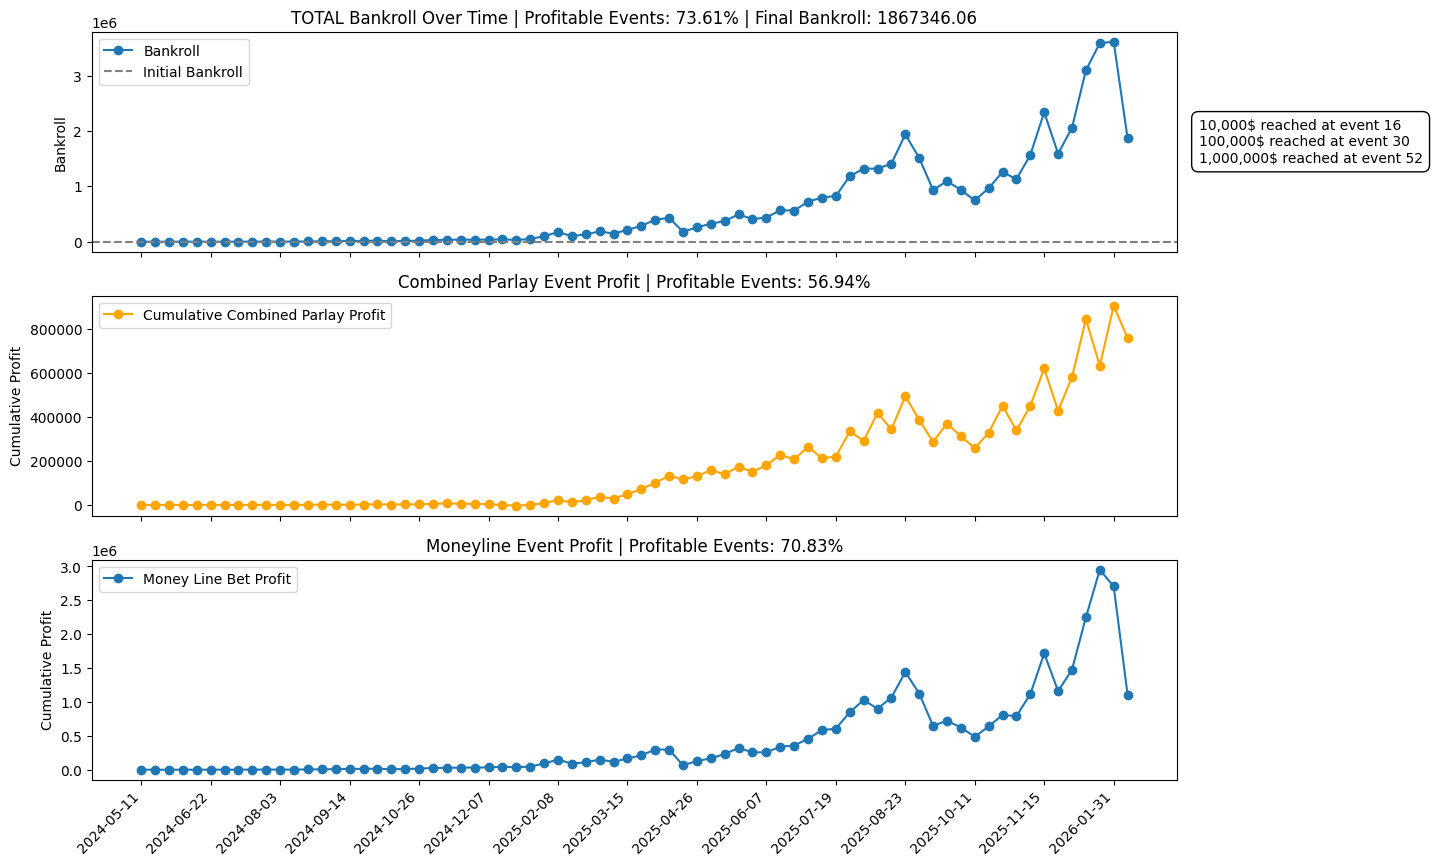

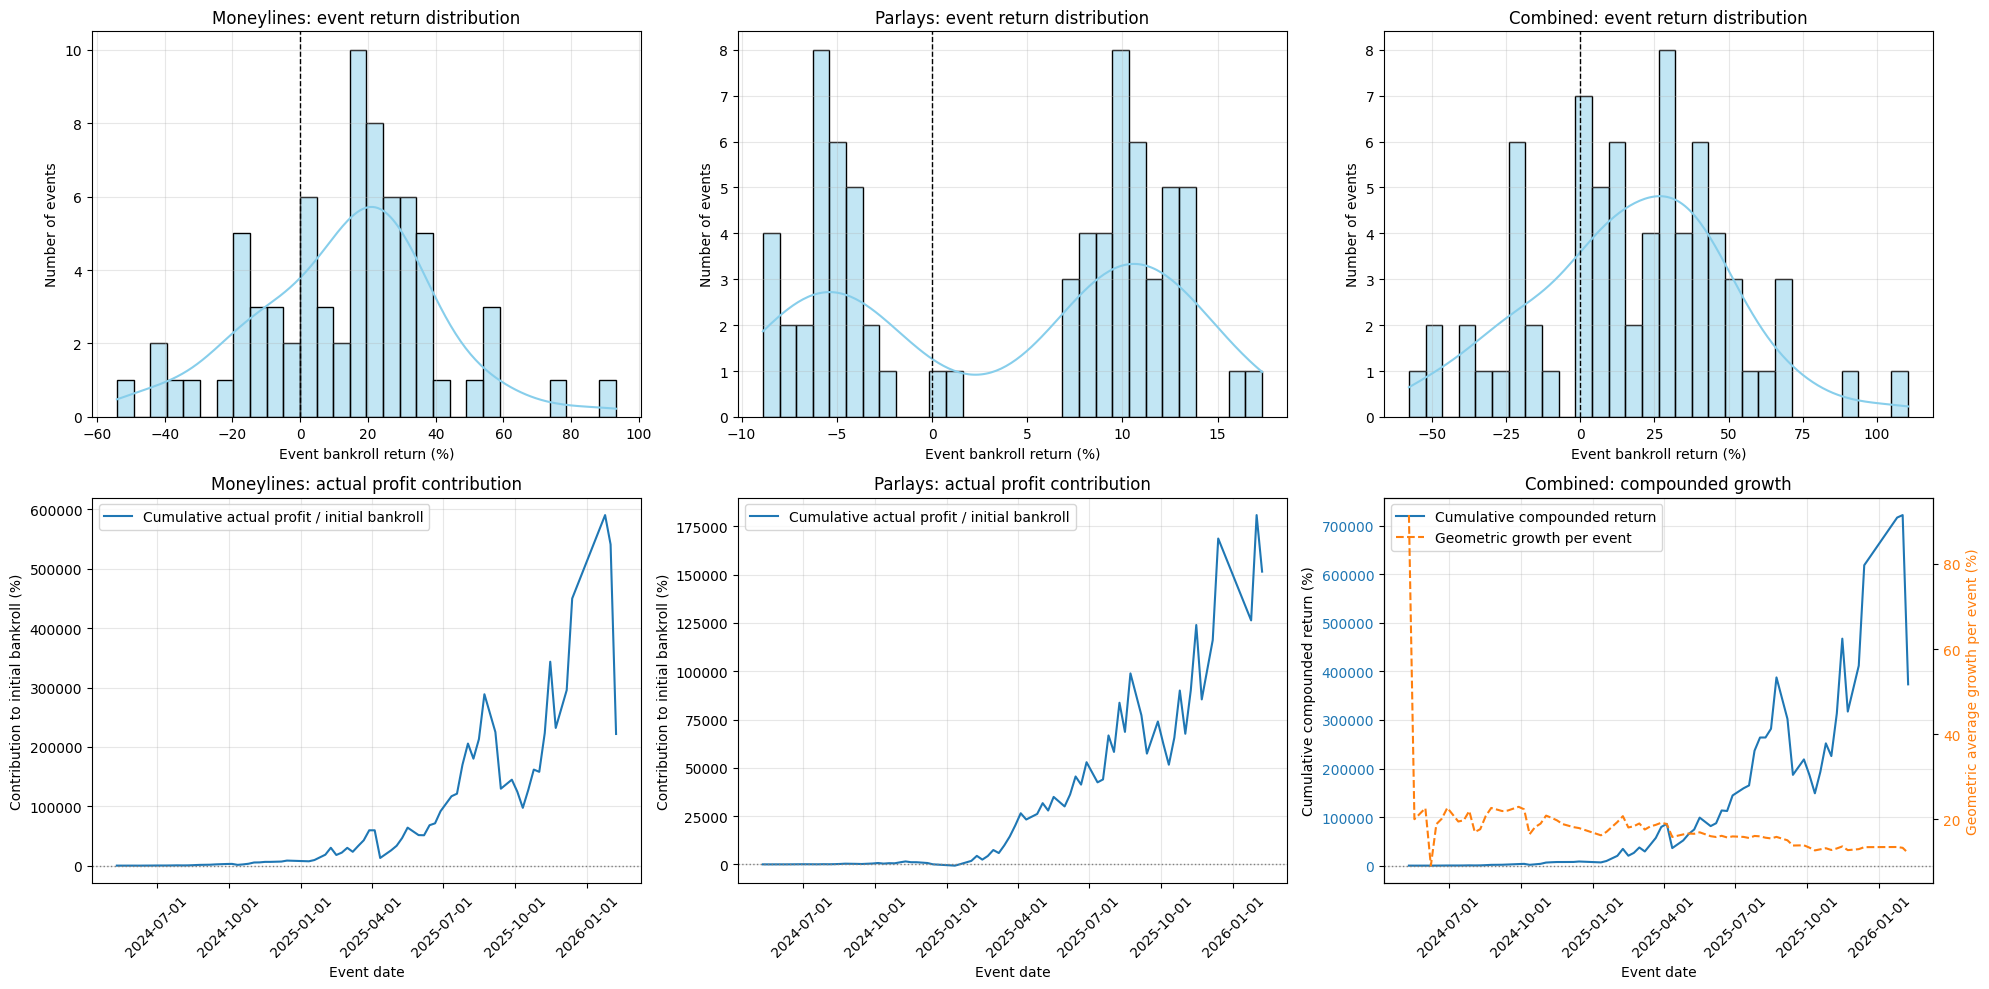

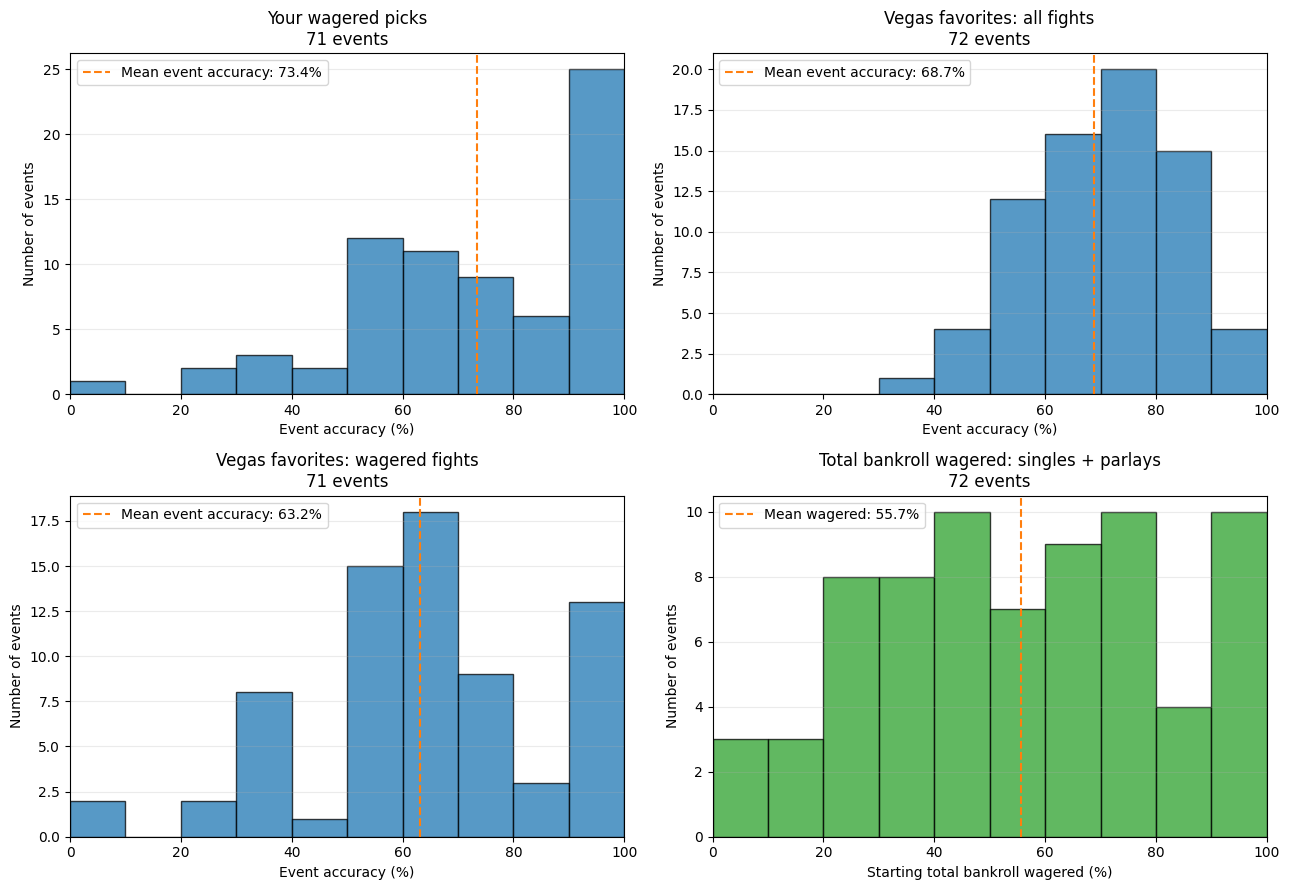

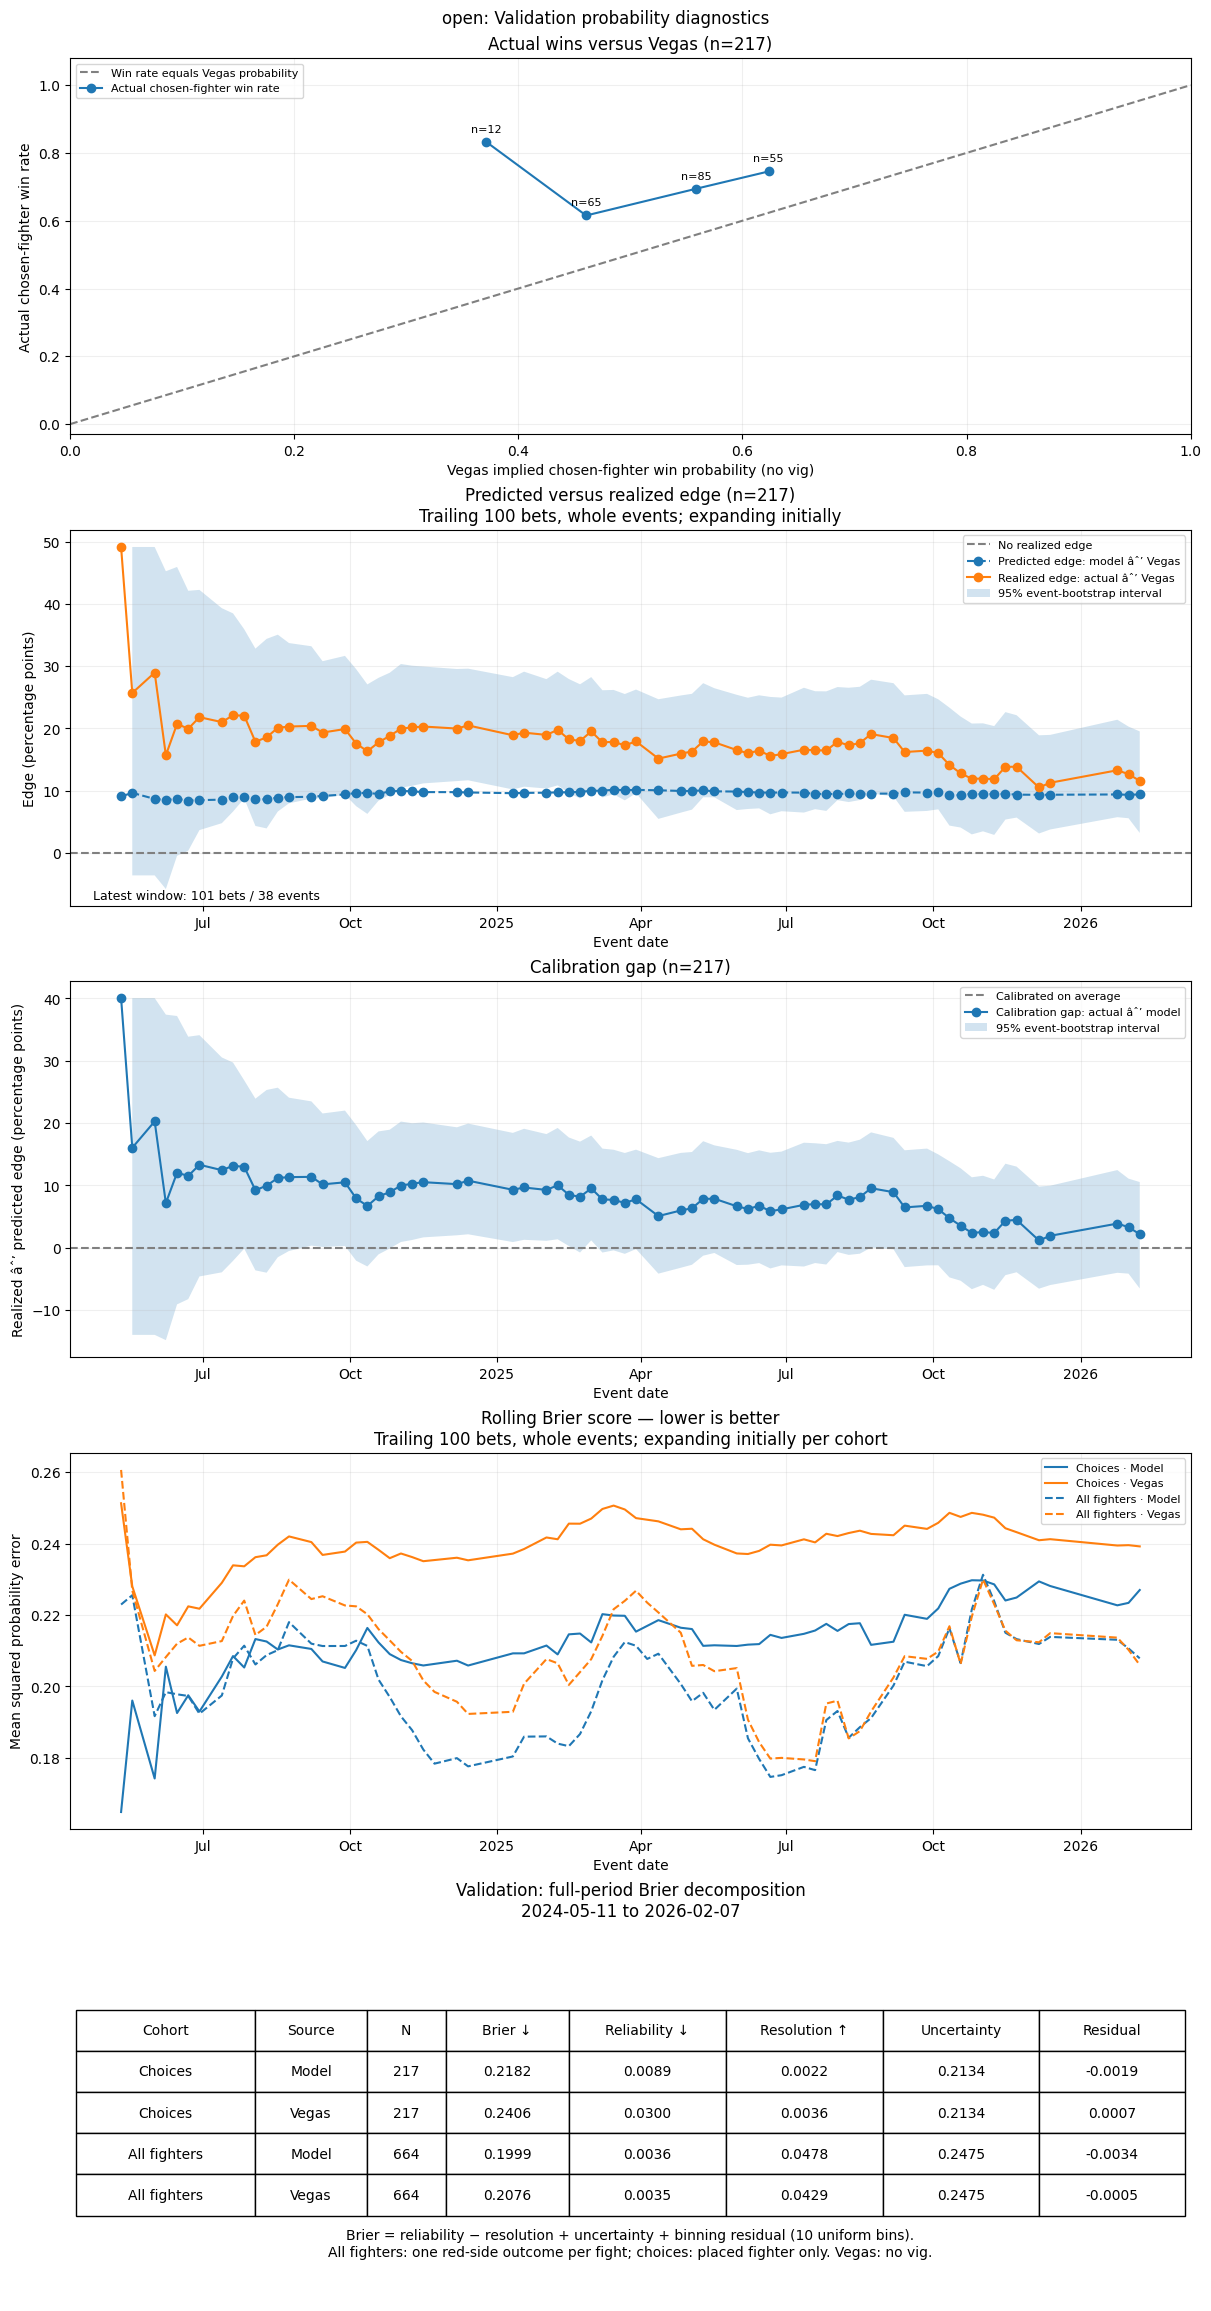

Saved moneylines, parlays, and plots: C:\Users\jcmar\my_files\SportsBetting\Data\backtest_results\model_comparisons\inference_market_models / train_val_open_with_open_inference_no_decay_*
Betting parameters: C:\Users\jcmar\my_files\SportsBetting\Data\kelly_params\inference_market_models\close1.json


c:\Users\jcmar\my_files\SportsBetting\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Predictions: C:\Users\jcmar\my_files\SportsBetting\Data\model_comparisons\lr_open_close\report_predictions\train\open\inference\val_with_close1.csv
close1: decay enabled


{'z': 0.16,
 'N': 503,
 'N_parlay': 35,
 'mdd': 0.1784824829702686,
 'mdd_parlay': 0.3054627182537779,
 'moneyline_max_american': None,
 'decay_rates': {'k_down': 0.00031125012412097424,
  'k_up': 7.935386156682709,
  'k_parlay_down': 1.7643685603439327,
  'k_parlay_up': 0.2173995565432818},
 'moneyline_min_american': -500.0}

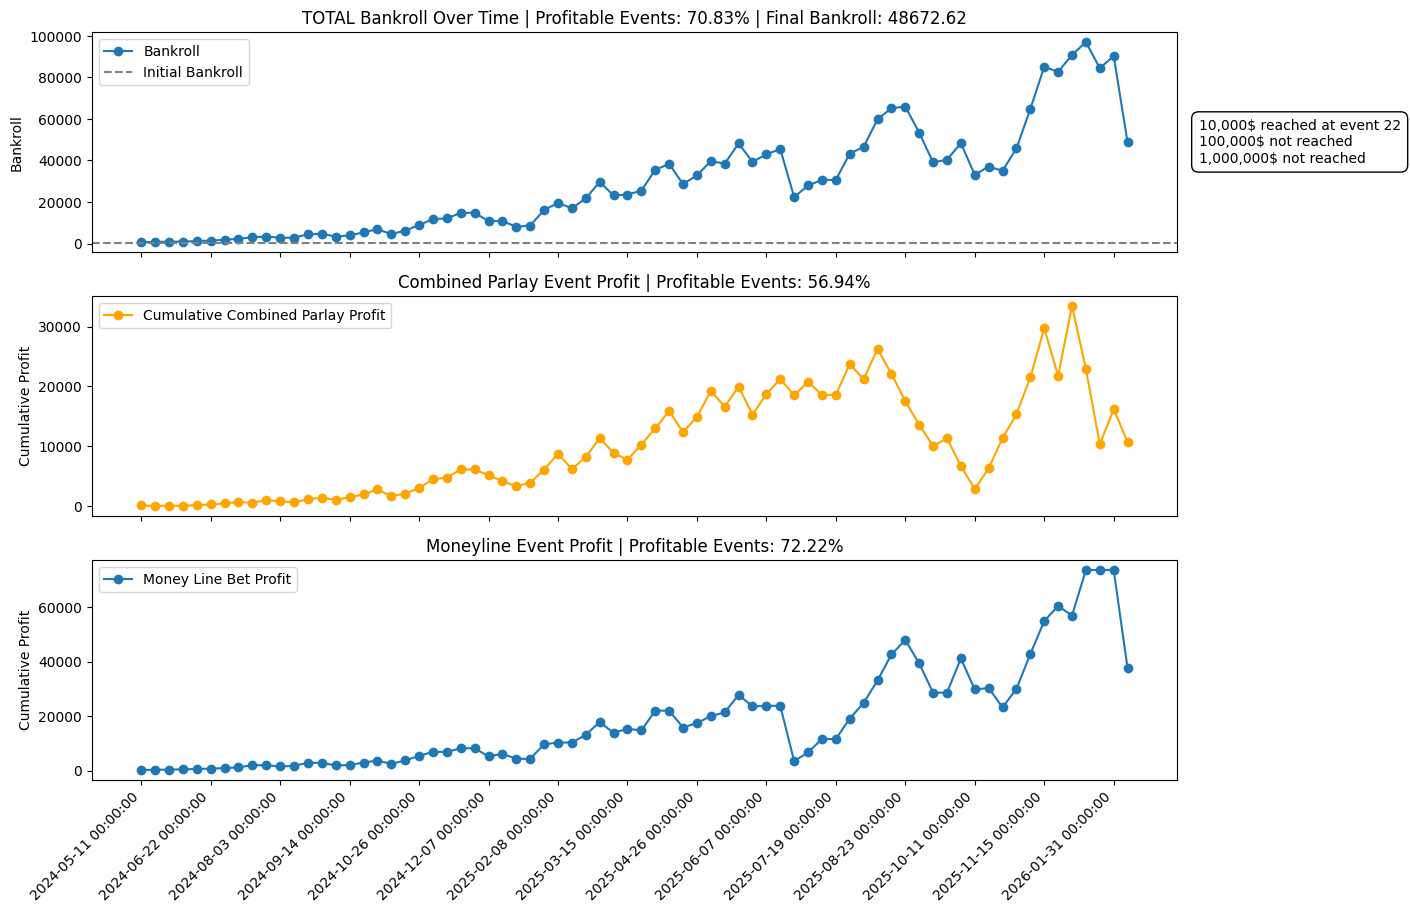

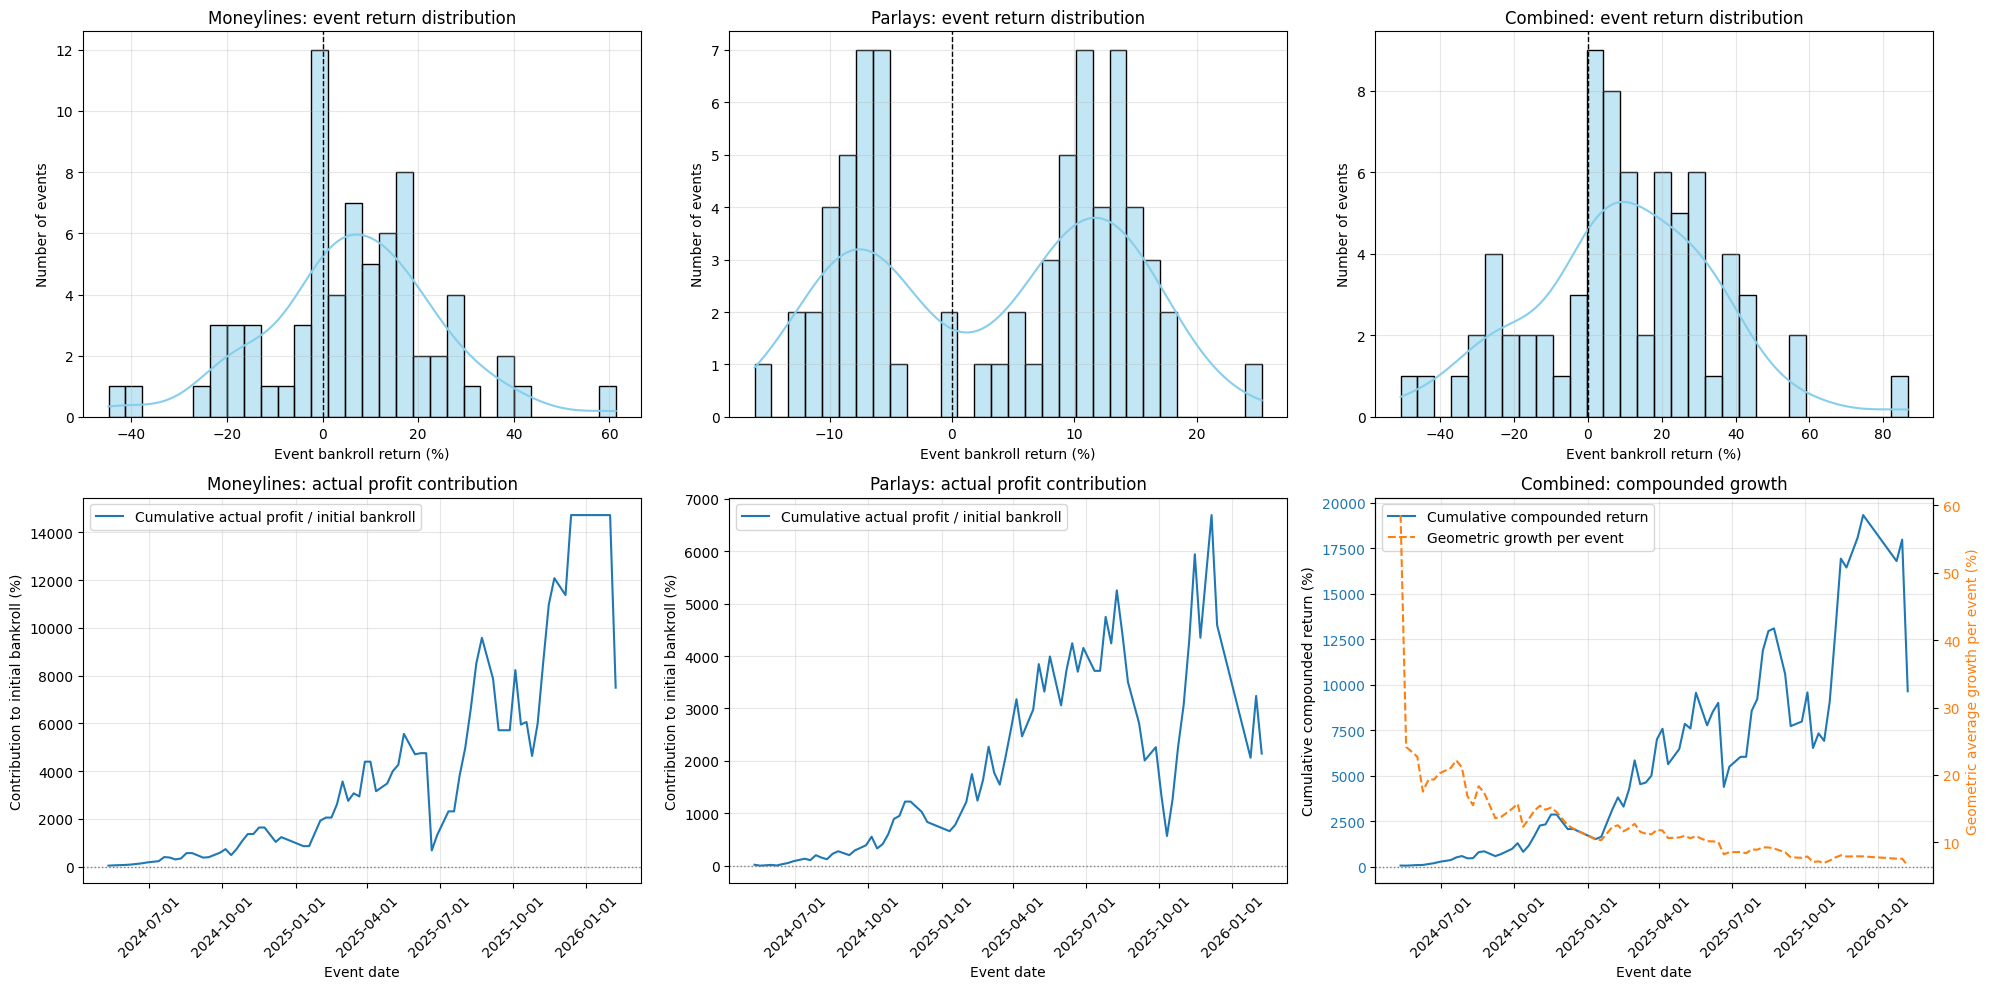

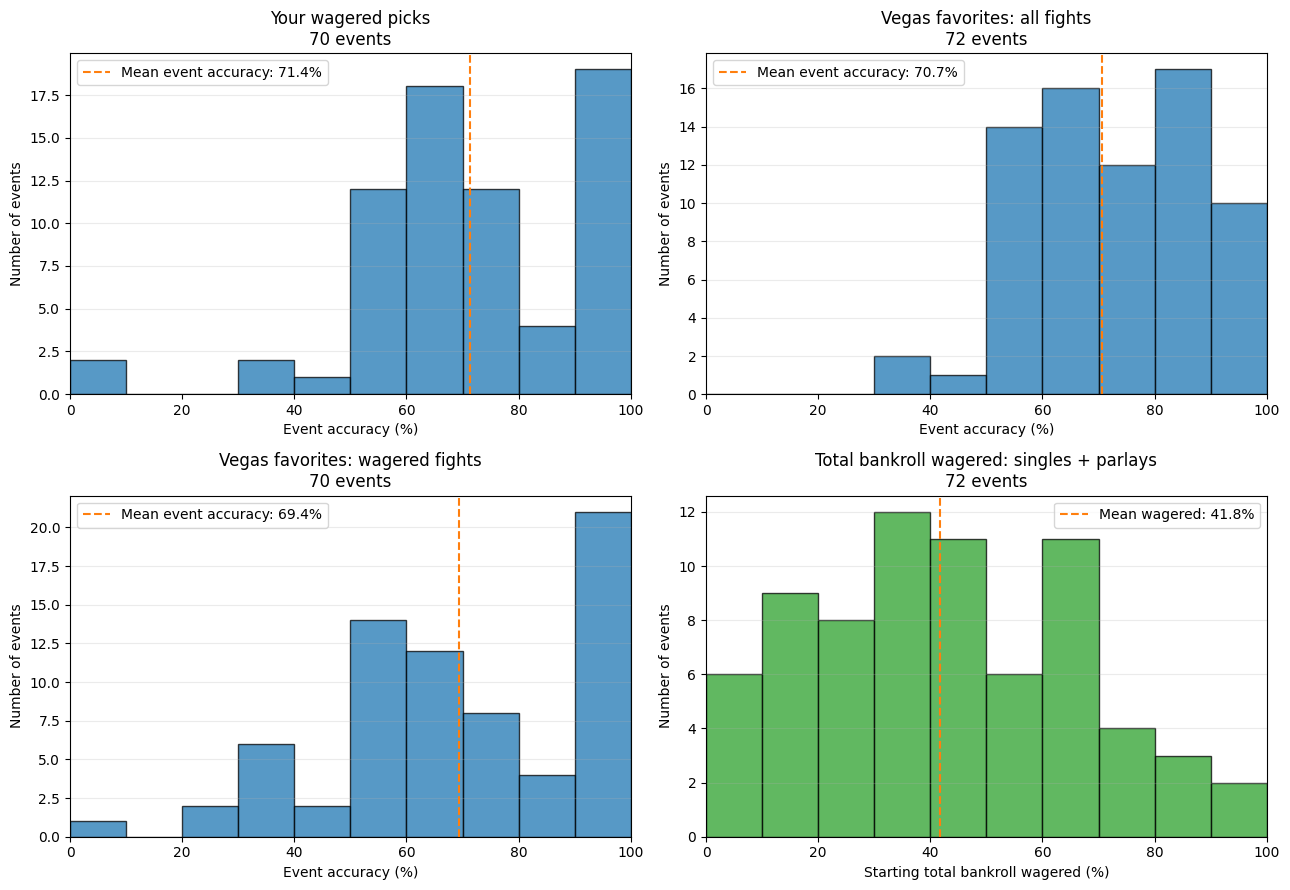

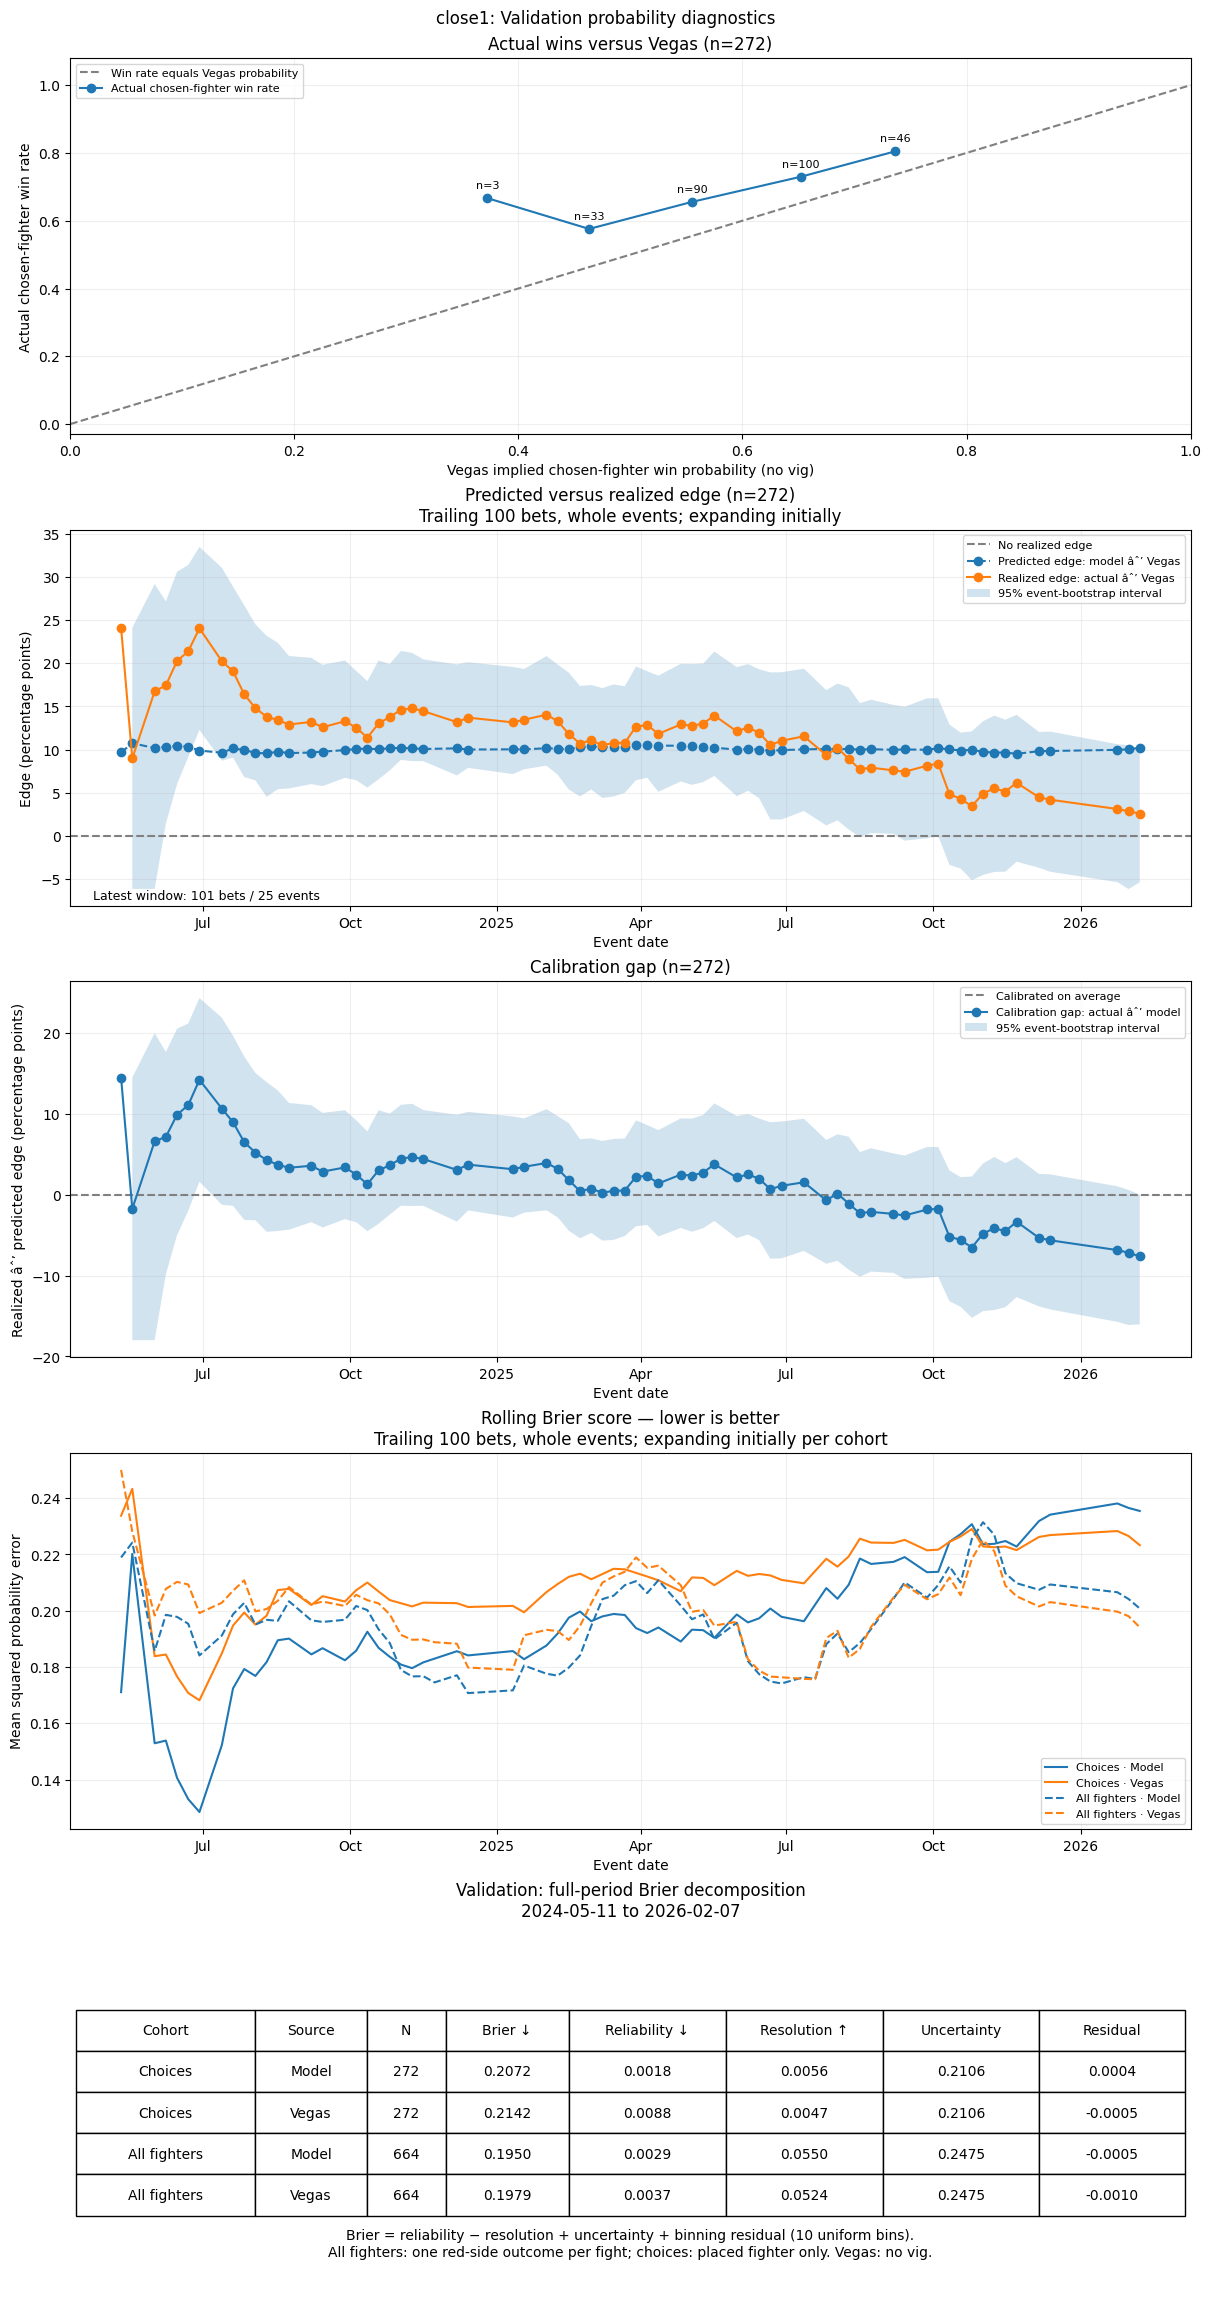

Saved moneylines, parlays, and plots: C:\Users\jcmar\my_files\SportsBetting\Data\backtest_results\model_comparisons\inference_market_models / train_val_open_with_close1_inference_decay_*
Betting parameters: C:\Users\jcmar\my_files\SportsBetting\Data\kelly_params\inference_market_models\close2.json
Predictions: C:\Users\jcmar\my_files\SportsBetting\Data\model_comparisons\lr_open_close\report_predictions\train\open\inference\val_with_close2.csv
close2: decay enabled


{'z': 0.33,
 'N': 213,
 'N_parlay': 1300,
 'mdd': 0.10234514216517145,
 'mdd_parlay': 0.05823236095383668,
 'moneyline_max_american': None,
 'decay_rates': {'k_down': 0.08478273961704863,
  'k_up': 46.20398693082857,
  'k_parlay_down': 0.20133184070455634,
  'k_parlay_up': 3.4085411178383067},
 'moneyline_min_american': -525.0}

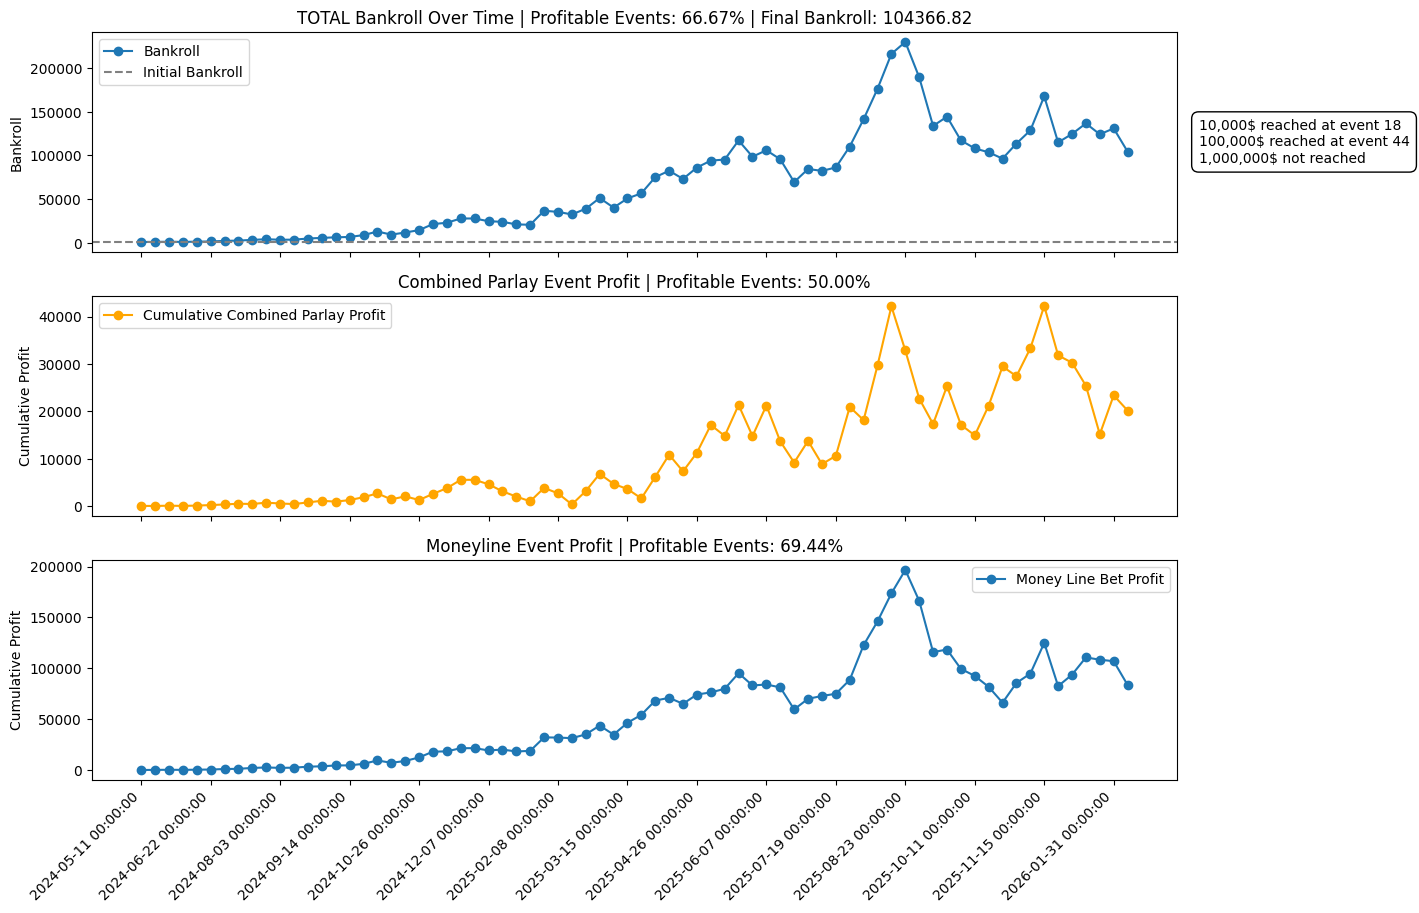

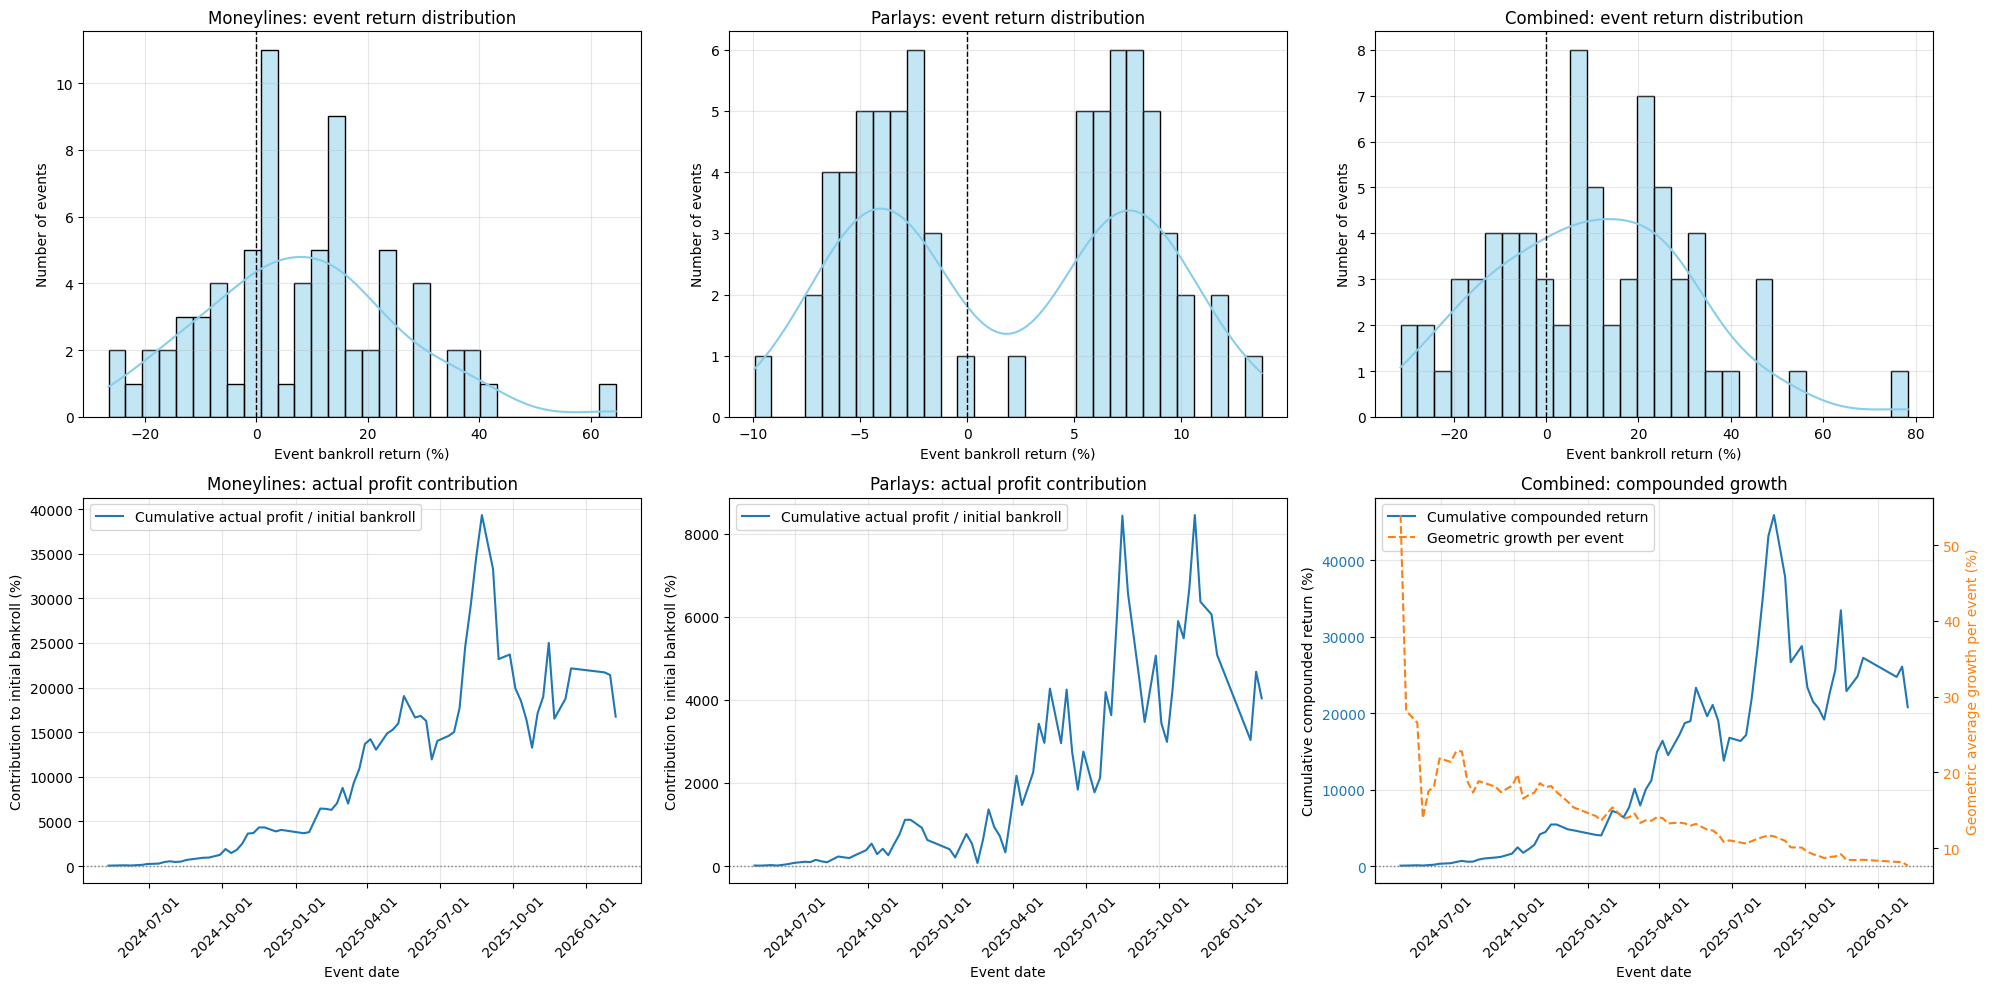

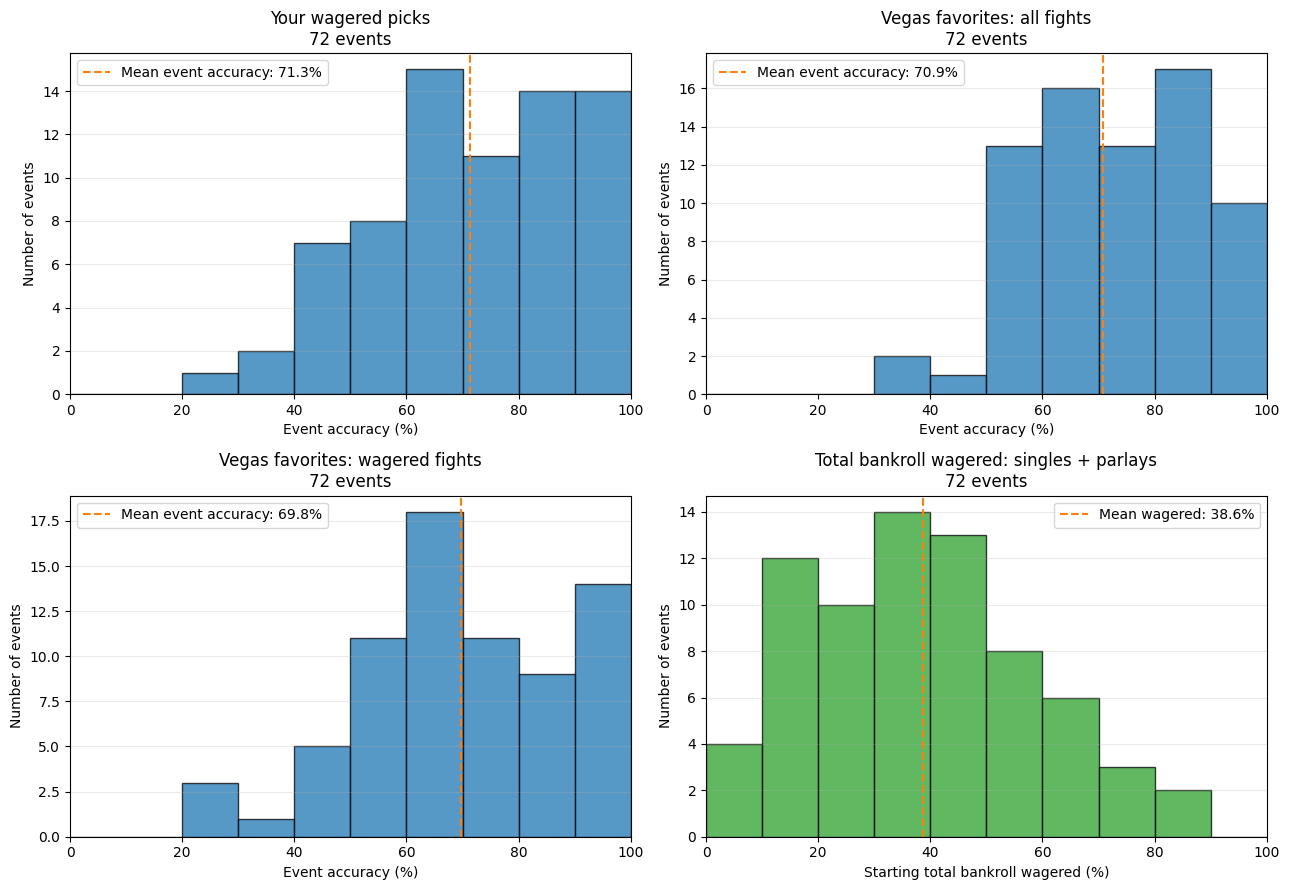

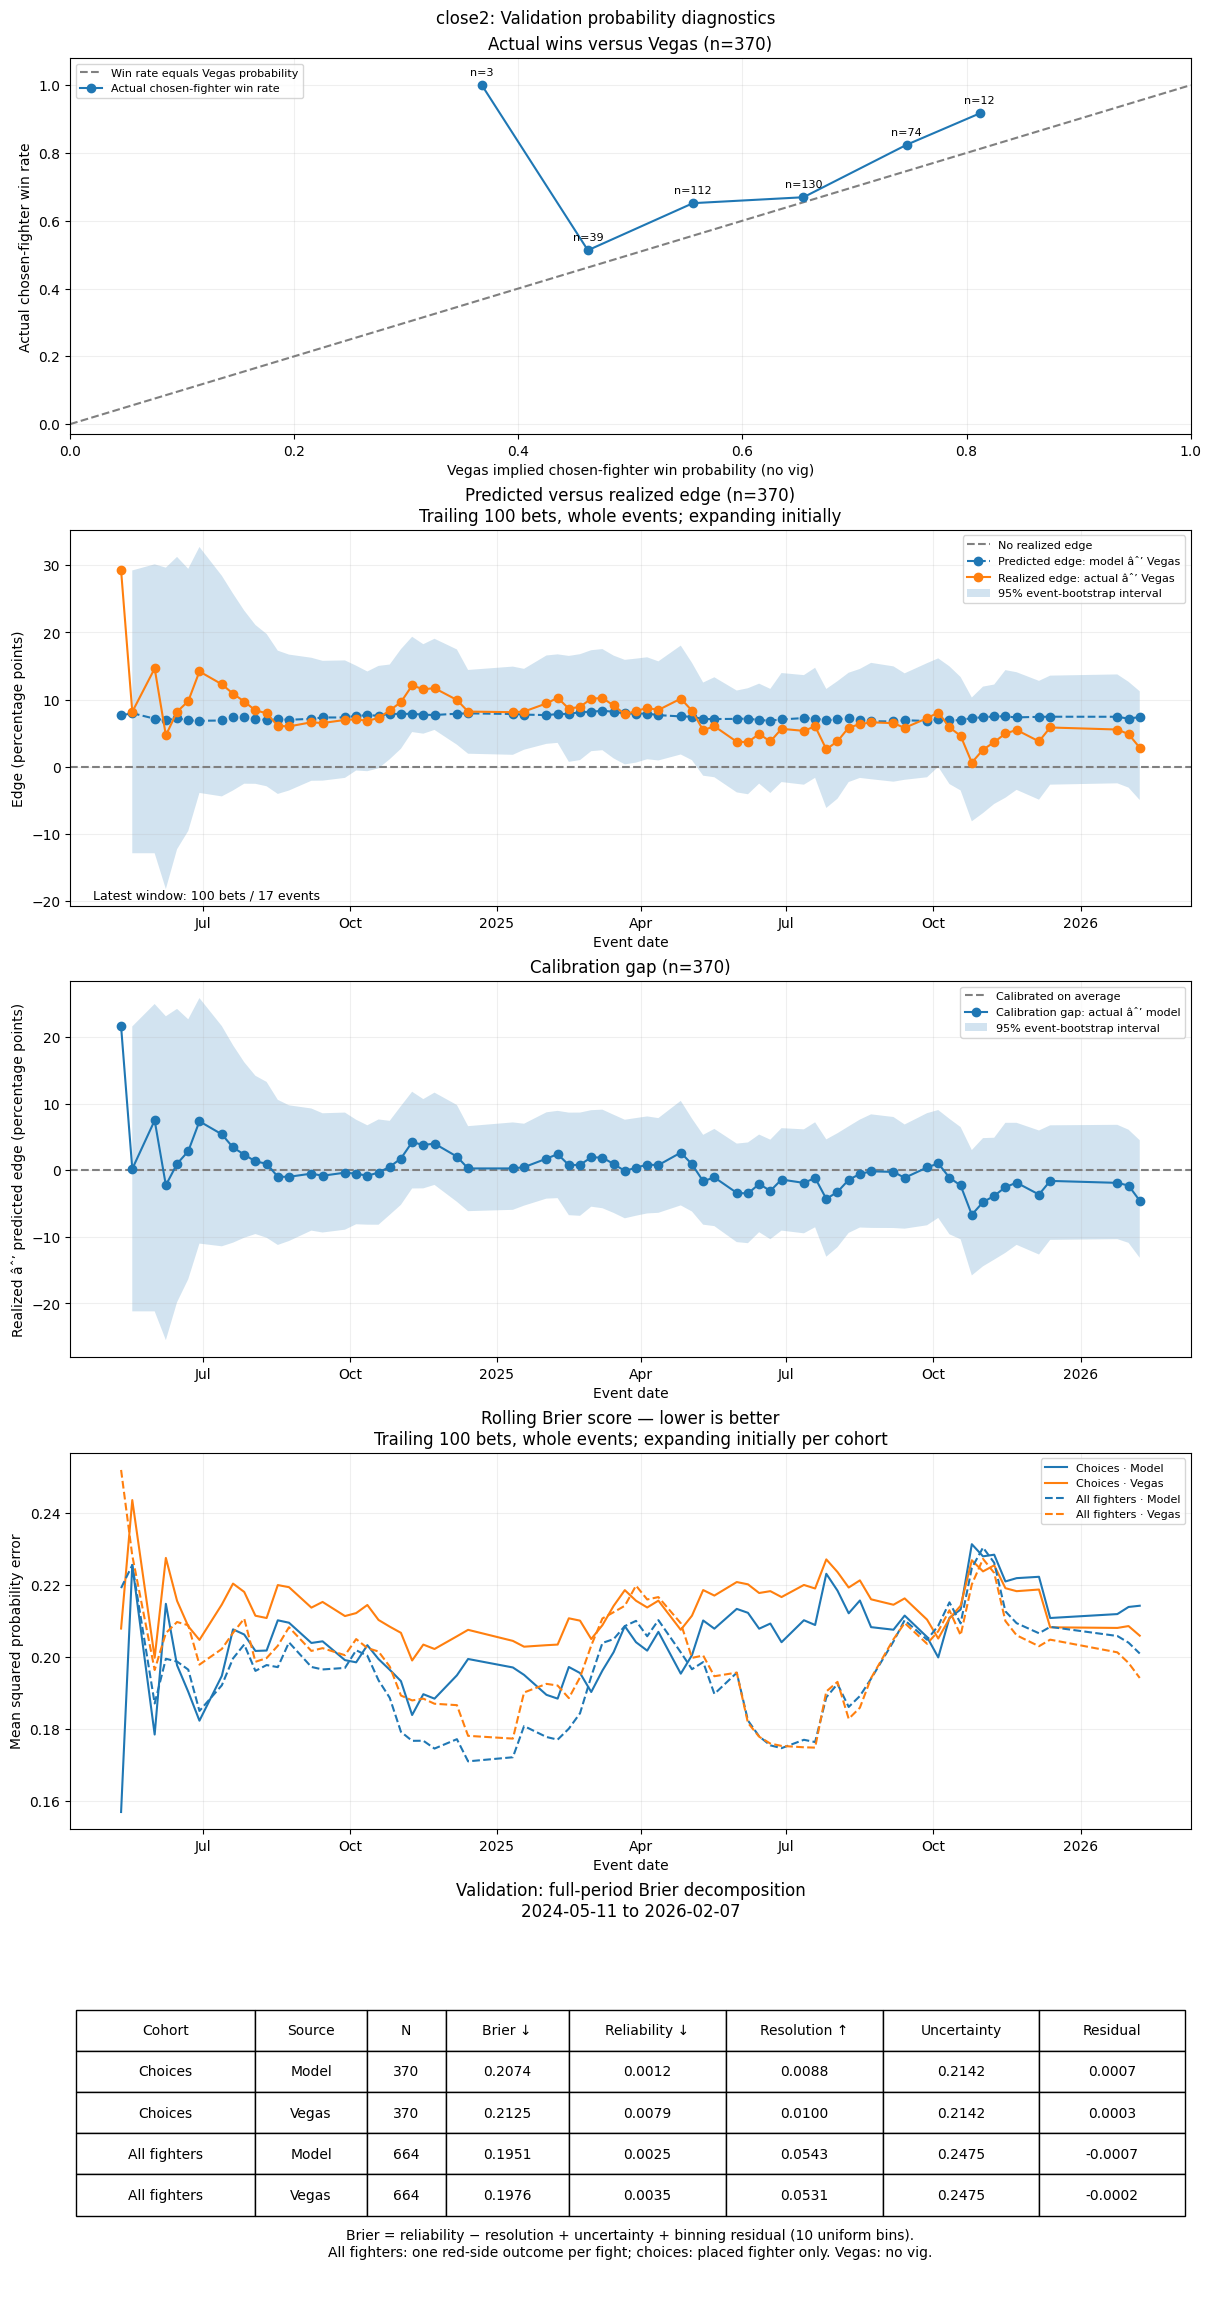

Saved moneylines, parlays, and plots: C:\Users\jcmar\my_files\SportsBetting\Data\backtest_results\model_comparisons\inference_market_models / train_val_open_with_close2_inference_decay_*


In [4]:
for market in ("open", "close1", "close2"):
    moneylines, parlays = plot_comparison_results(
        fit_mode="train",
        model_type='open',
        probability_model="inference",
        split="val",
        odds_type=market,
        params_dir=settings.data_dir / "kelly_params/inference_market_models",
    )

Betting parameters: C:\Users\jcmar\my_files\SportsBetting\Data\kelly_params\open.json
Predictions: C:\Users\jcmar\my_files\SportsBetting\Data\model_comparisons\lr_open_close\report_predictions\train\open\regularized\val_with_open.csv
open: decay disabled


{'z': 0.32,
 'N': 58,
 'N_parlay': 22,
 'mdd': 0.31,
 'mdd_parlay': 0.17,
 'moneyline_max_american': None,
 'decay_rates': None,
 'moneyline_min_american': -500.0}

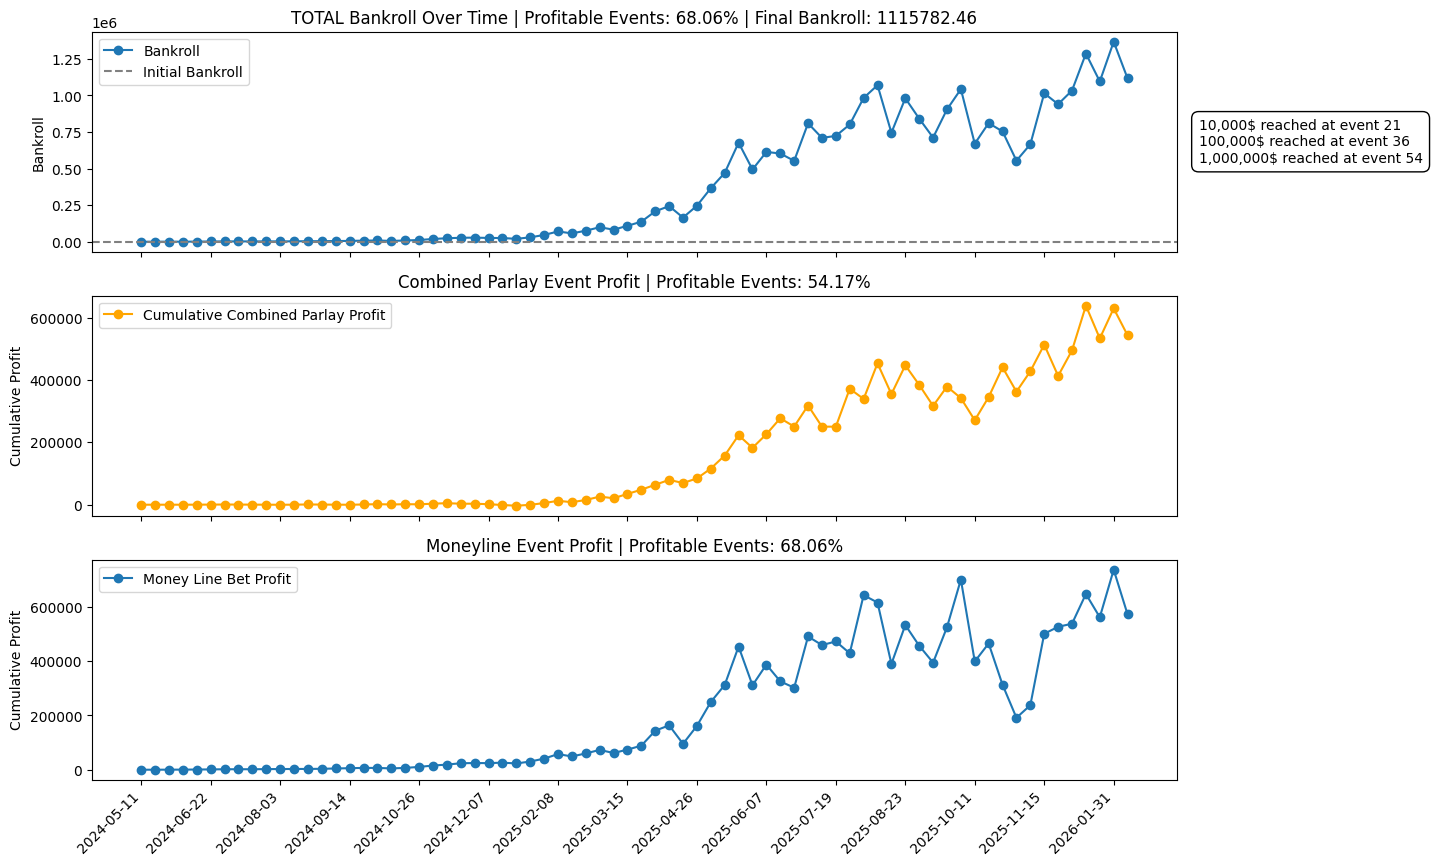

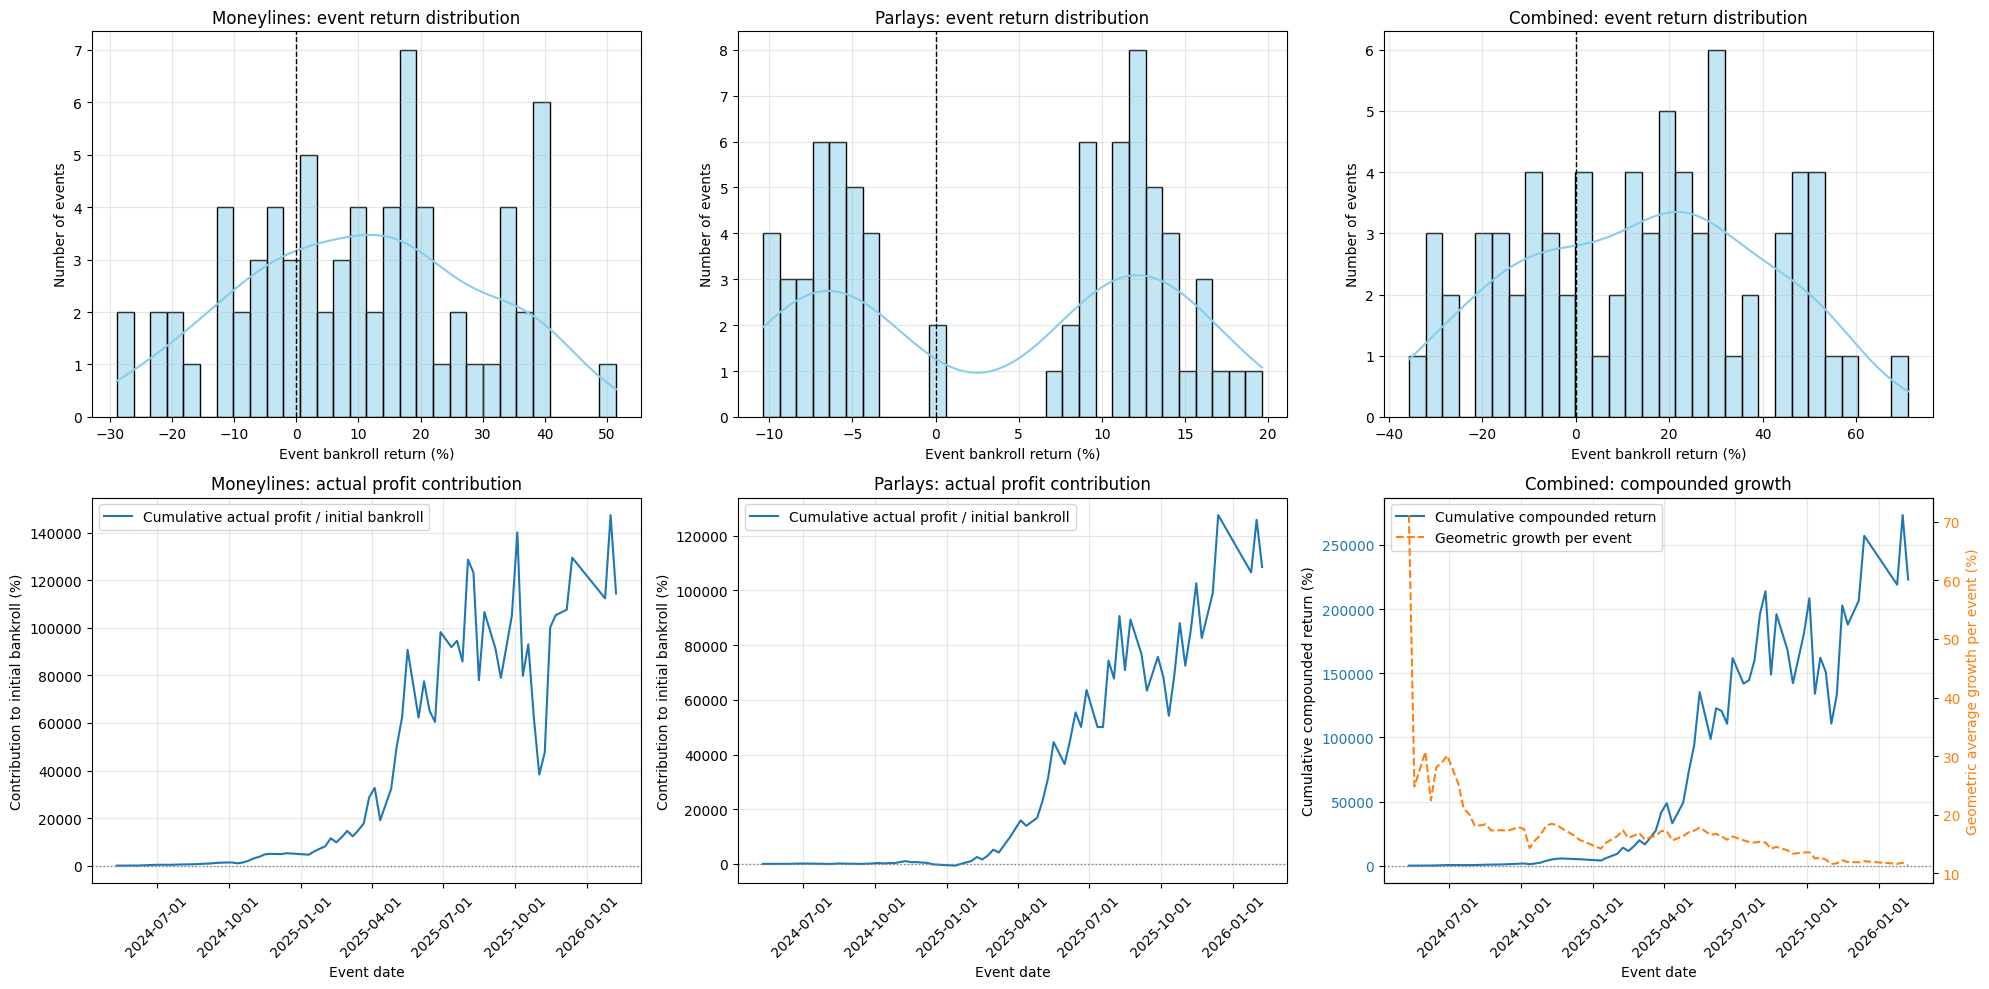

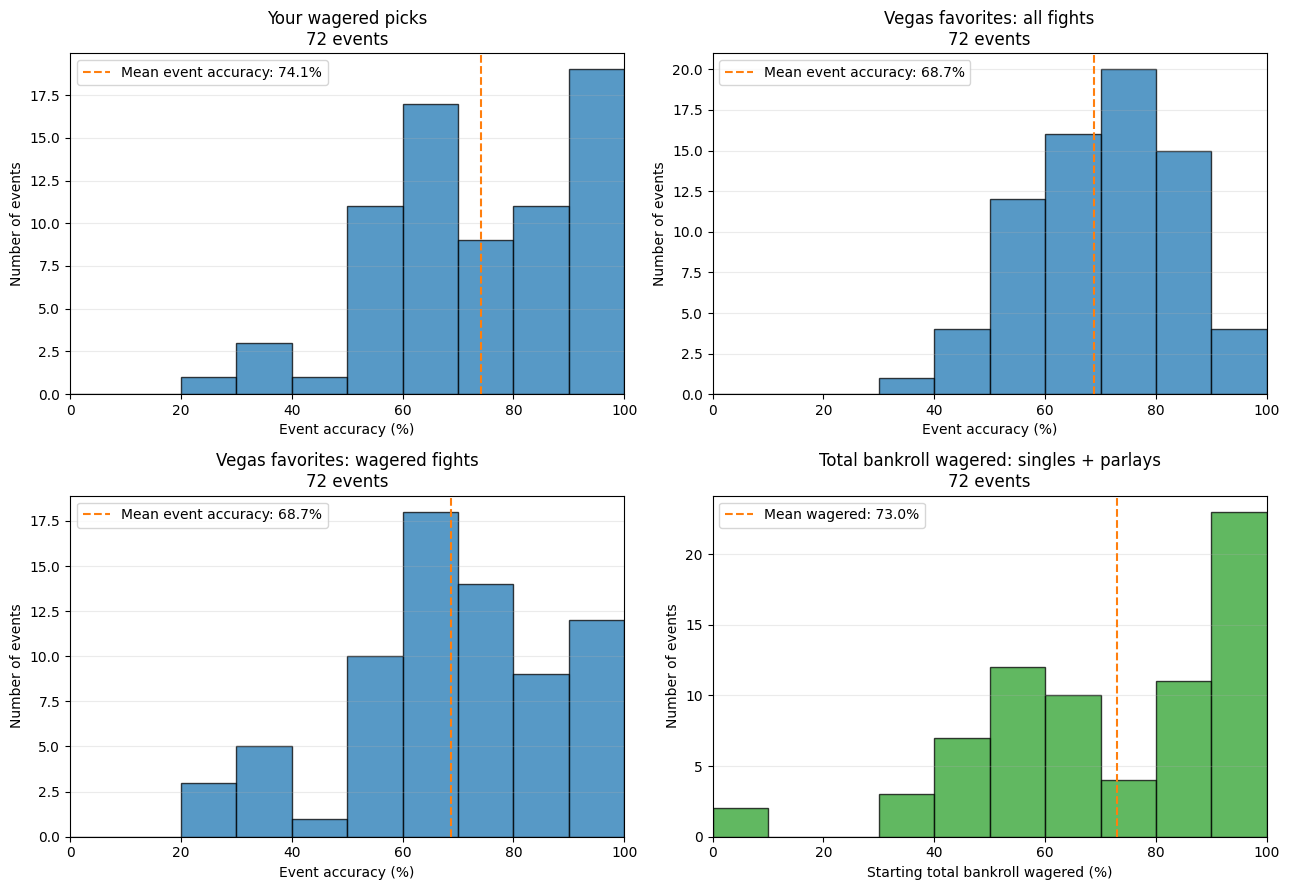

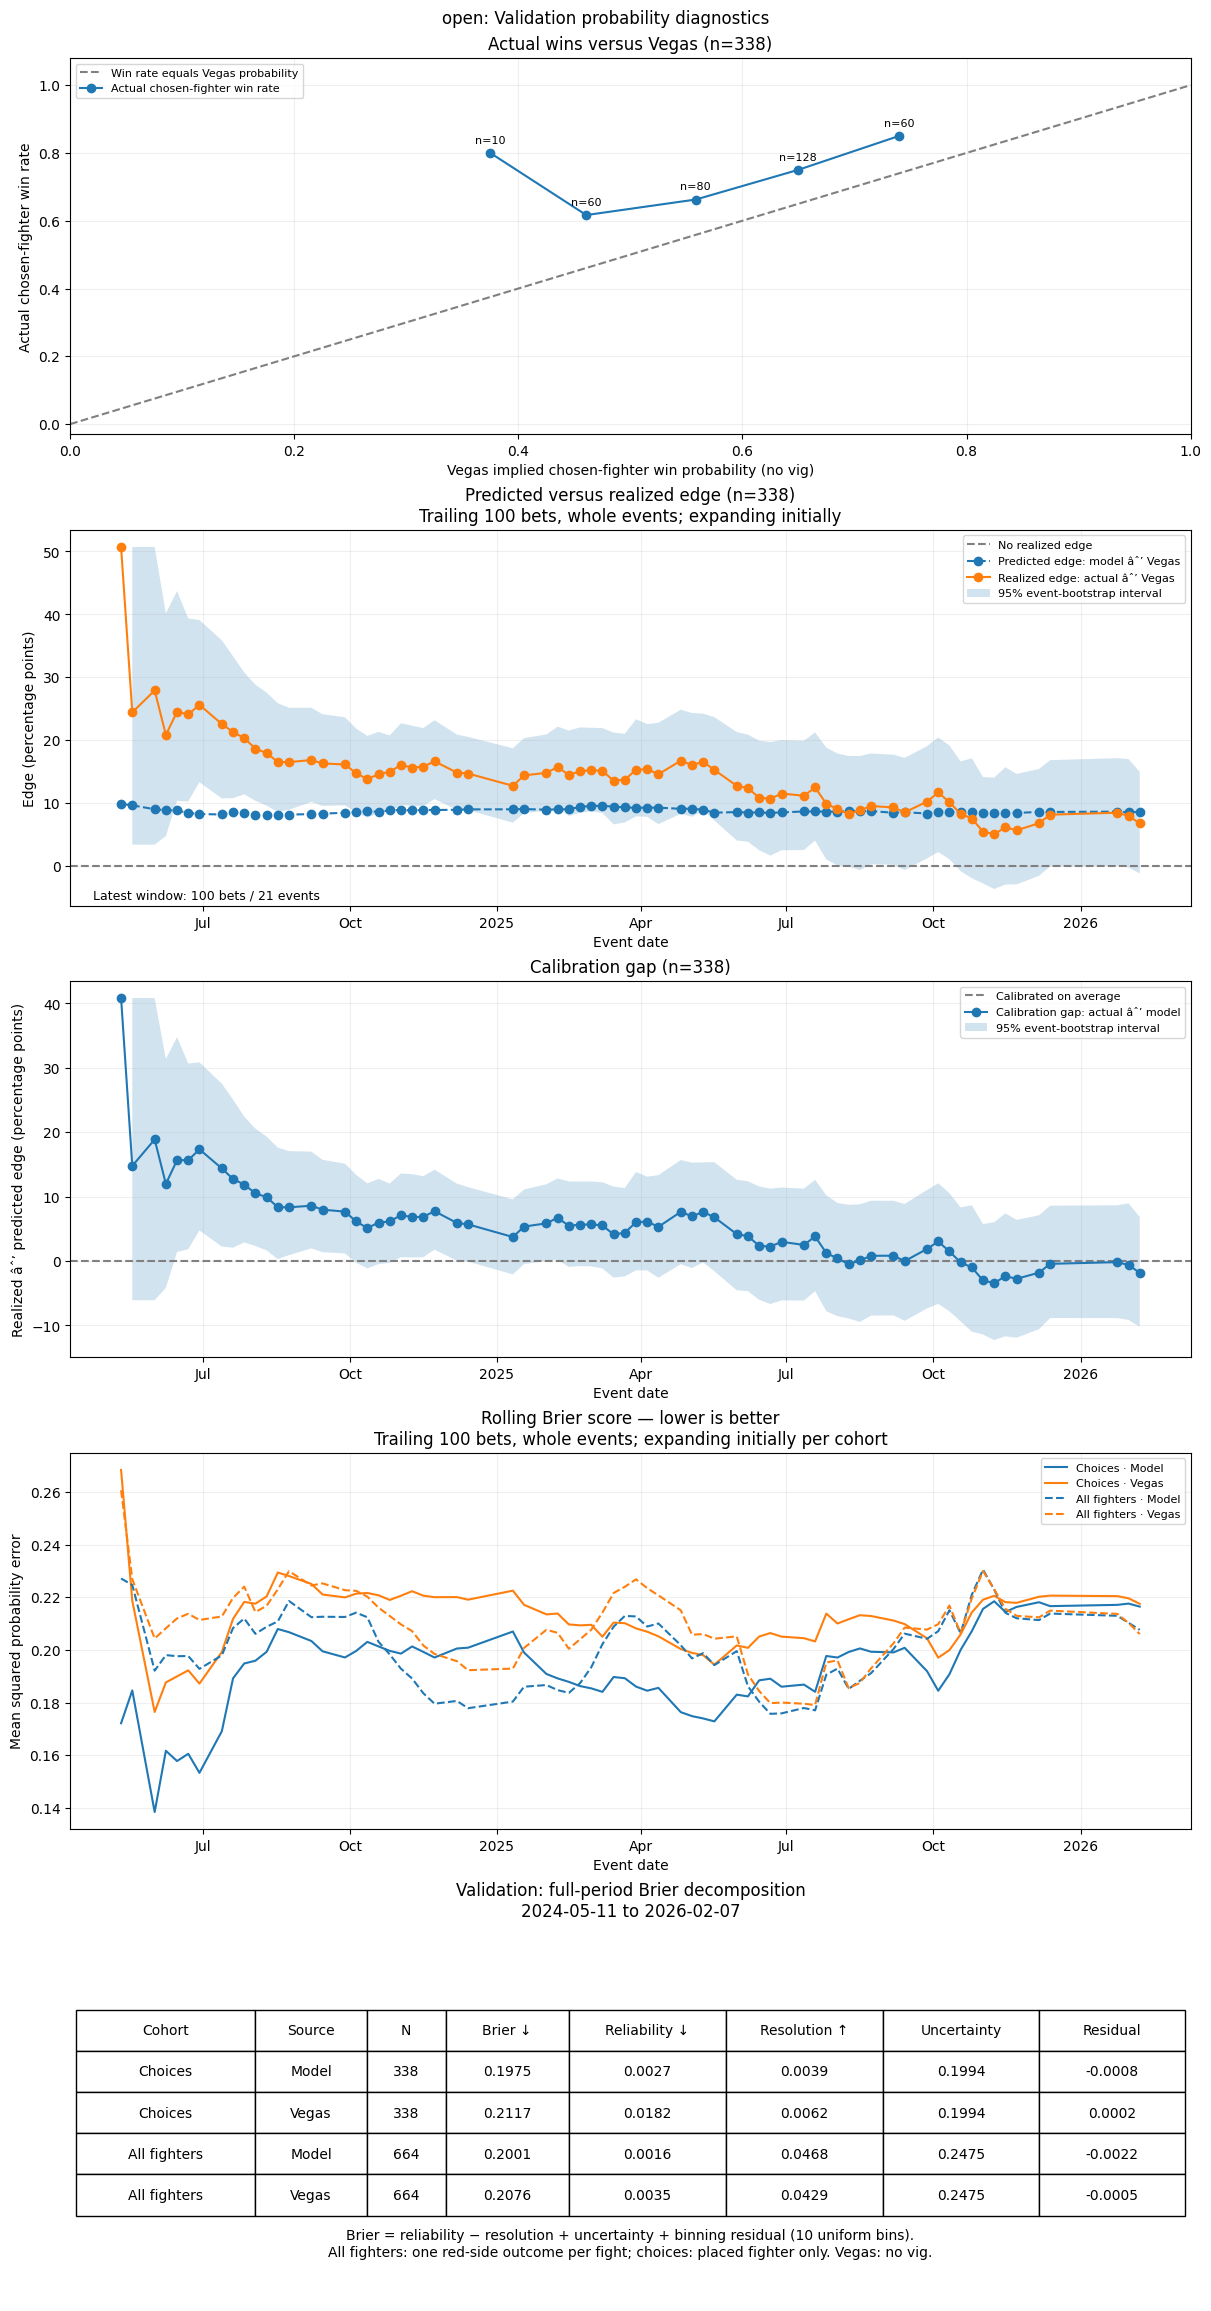

Saved moneylines, parlays, and plots: C:\Users\jcmar\my_files\SportsBetting\Data\backtest_results\model_comparisons\kelly_params / train_val_open_with_open_regularized_no_decay_*
Betting parameters: C:\Users\jcmar\my_files\SportsBetting\Data\kelly_params\close1.json
Predictions: C:\Users\jcmar\my_files\SportsBetting\Data\model_comparisons\lr_open_close\report_predictions\train\open\regularized\val_with_close1.csv
close1: decay enabled


{'z': 1.33,
 'N': 1090,
 'N_parlay': 964,
 'mdd': 0.5800000000000001,
 'mdd_parlay': 0.01,
 'moneyline_max_american': None,
 'decay_rates': {'k_down': 41.04241524345824,
  'k_up': 0.3849900028407934,
  'k_parlay_down': 15.445551695494085,
  'k_parlay_up': 28.771654125641508},
 'moneyline_min_american': -225.0}

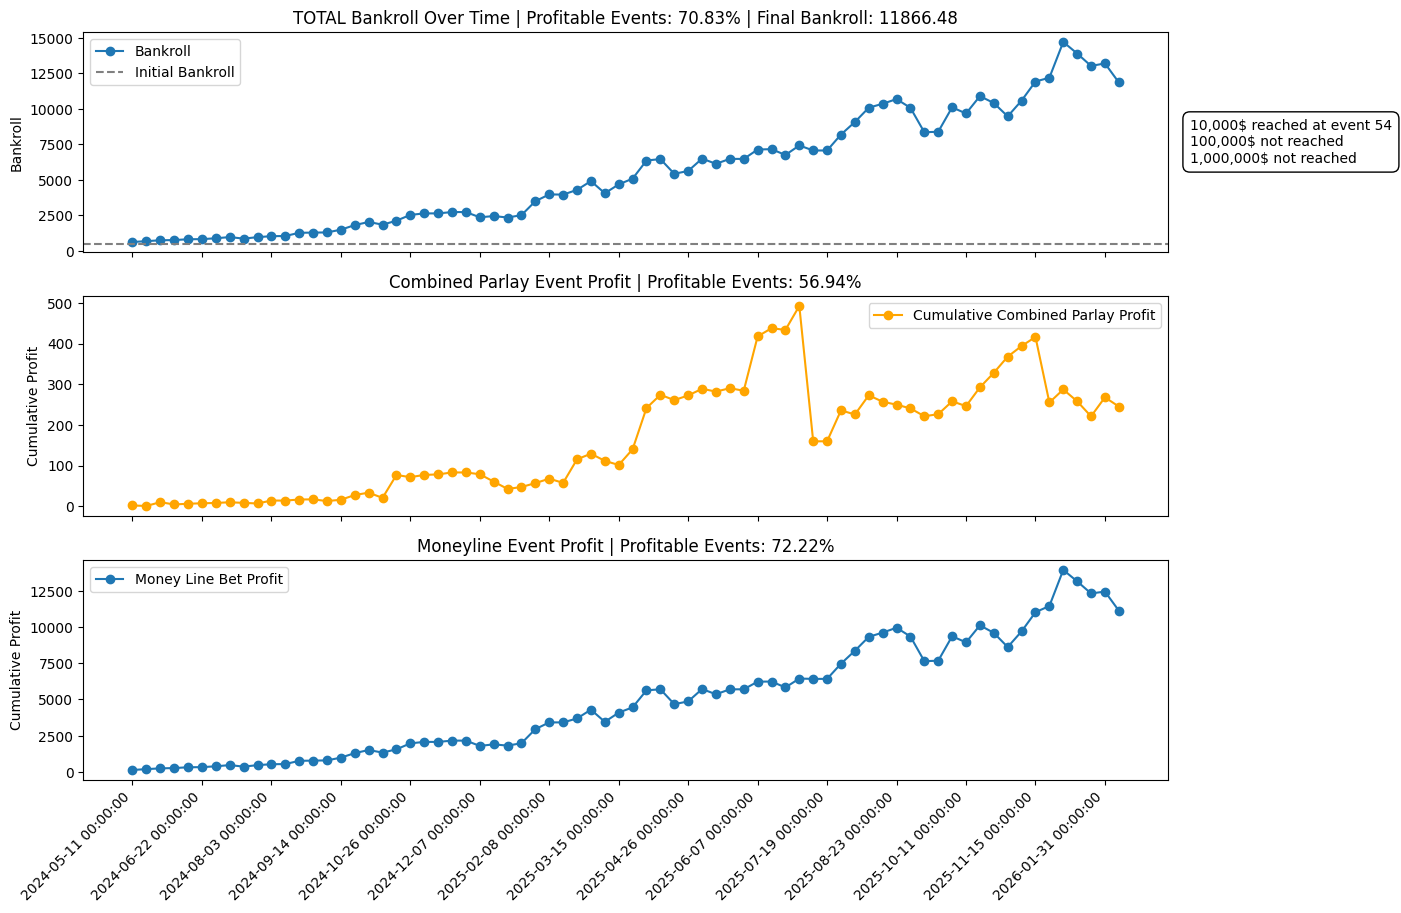

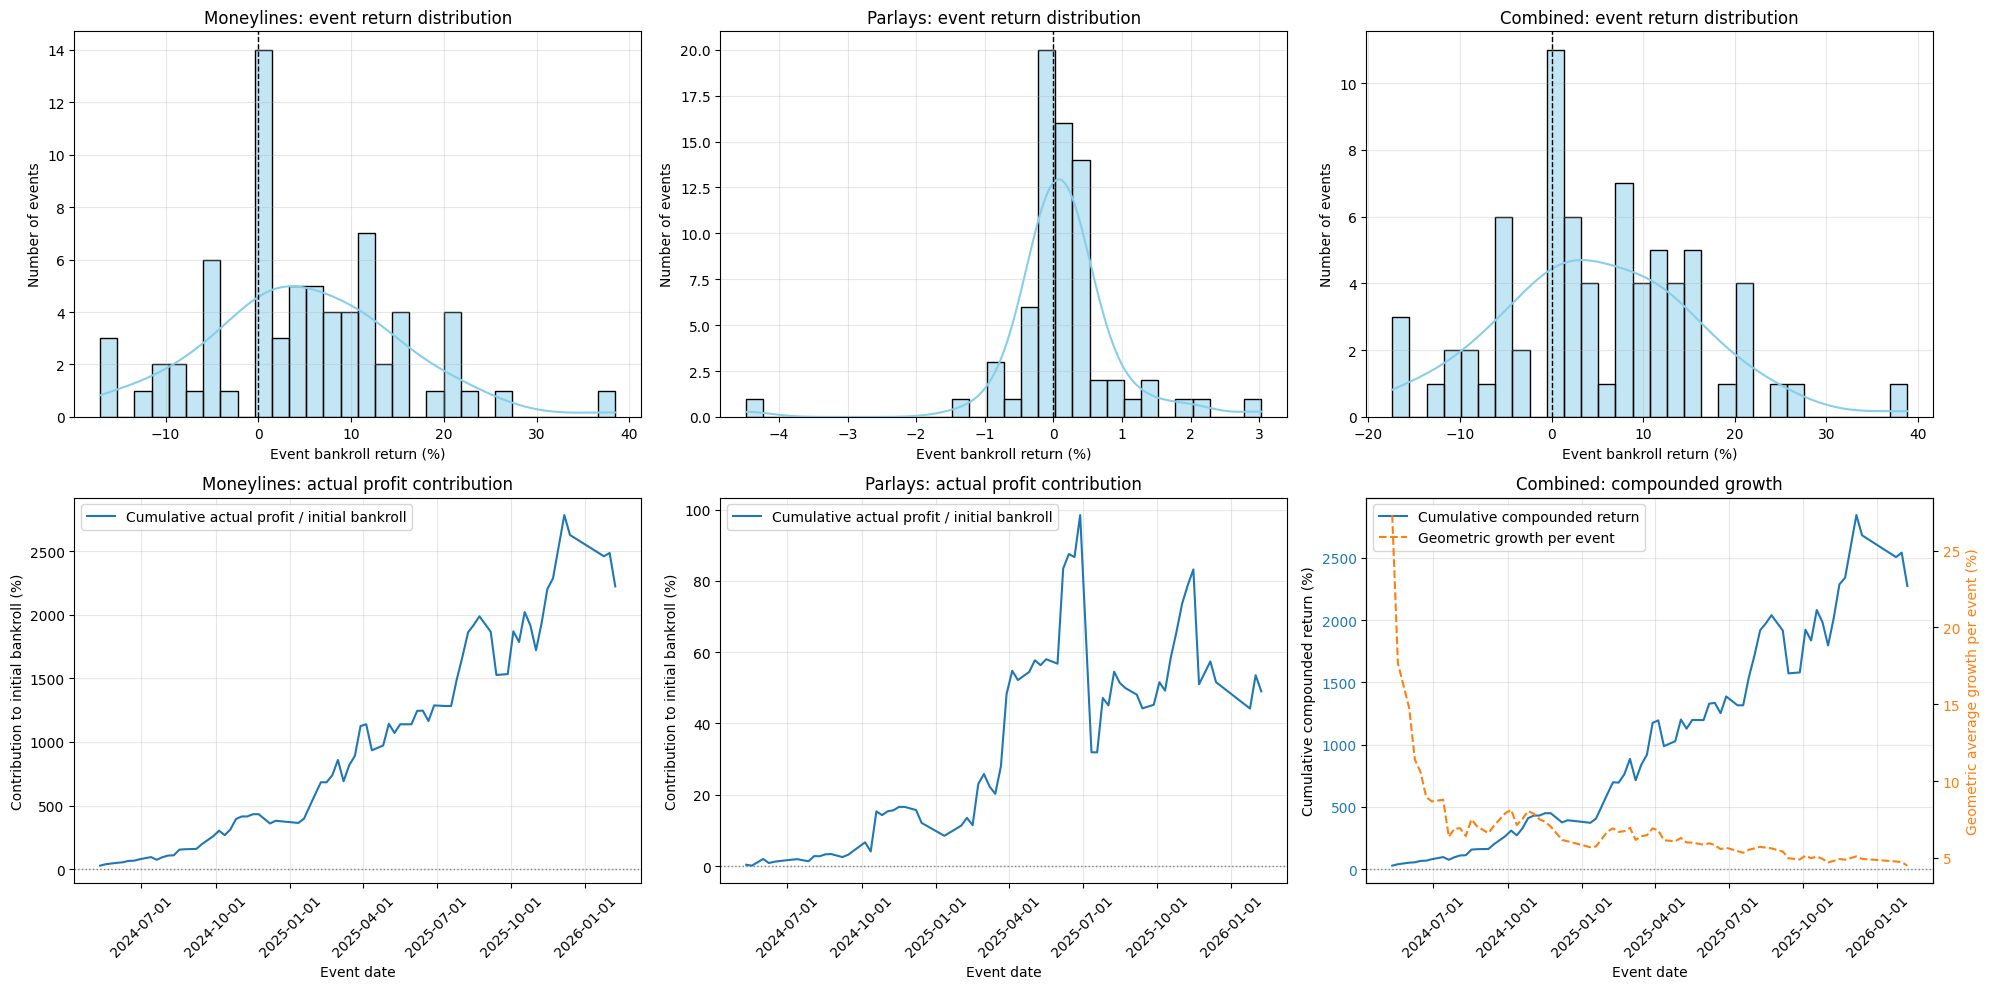

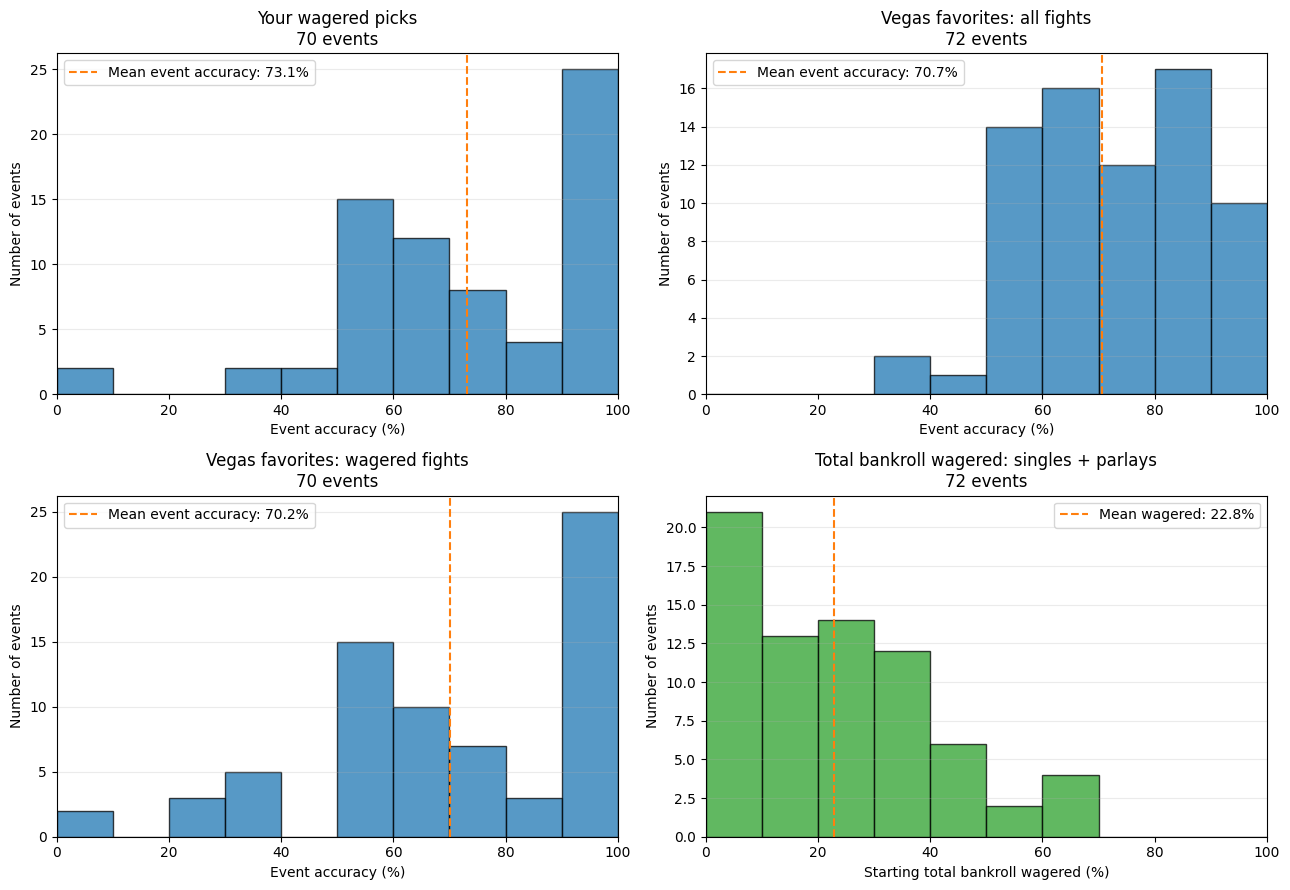

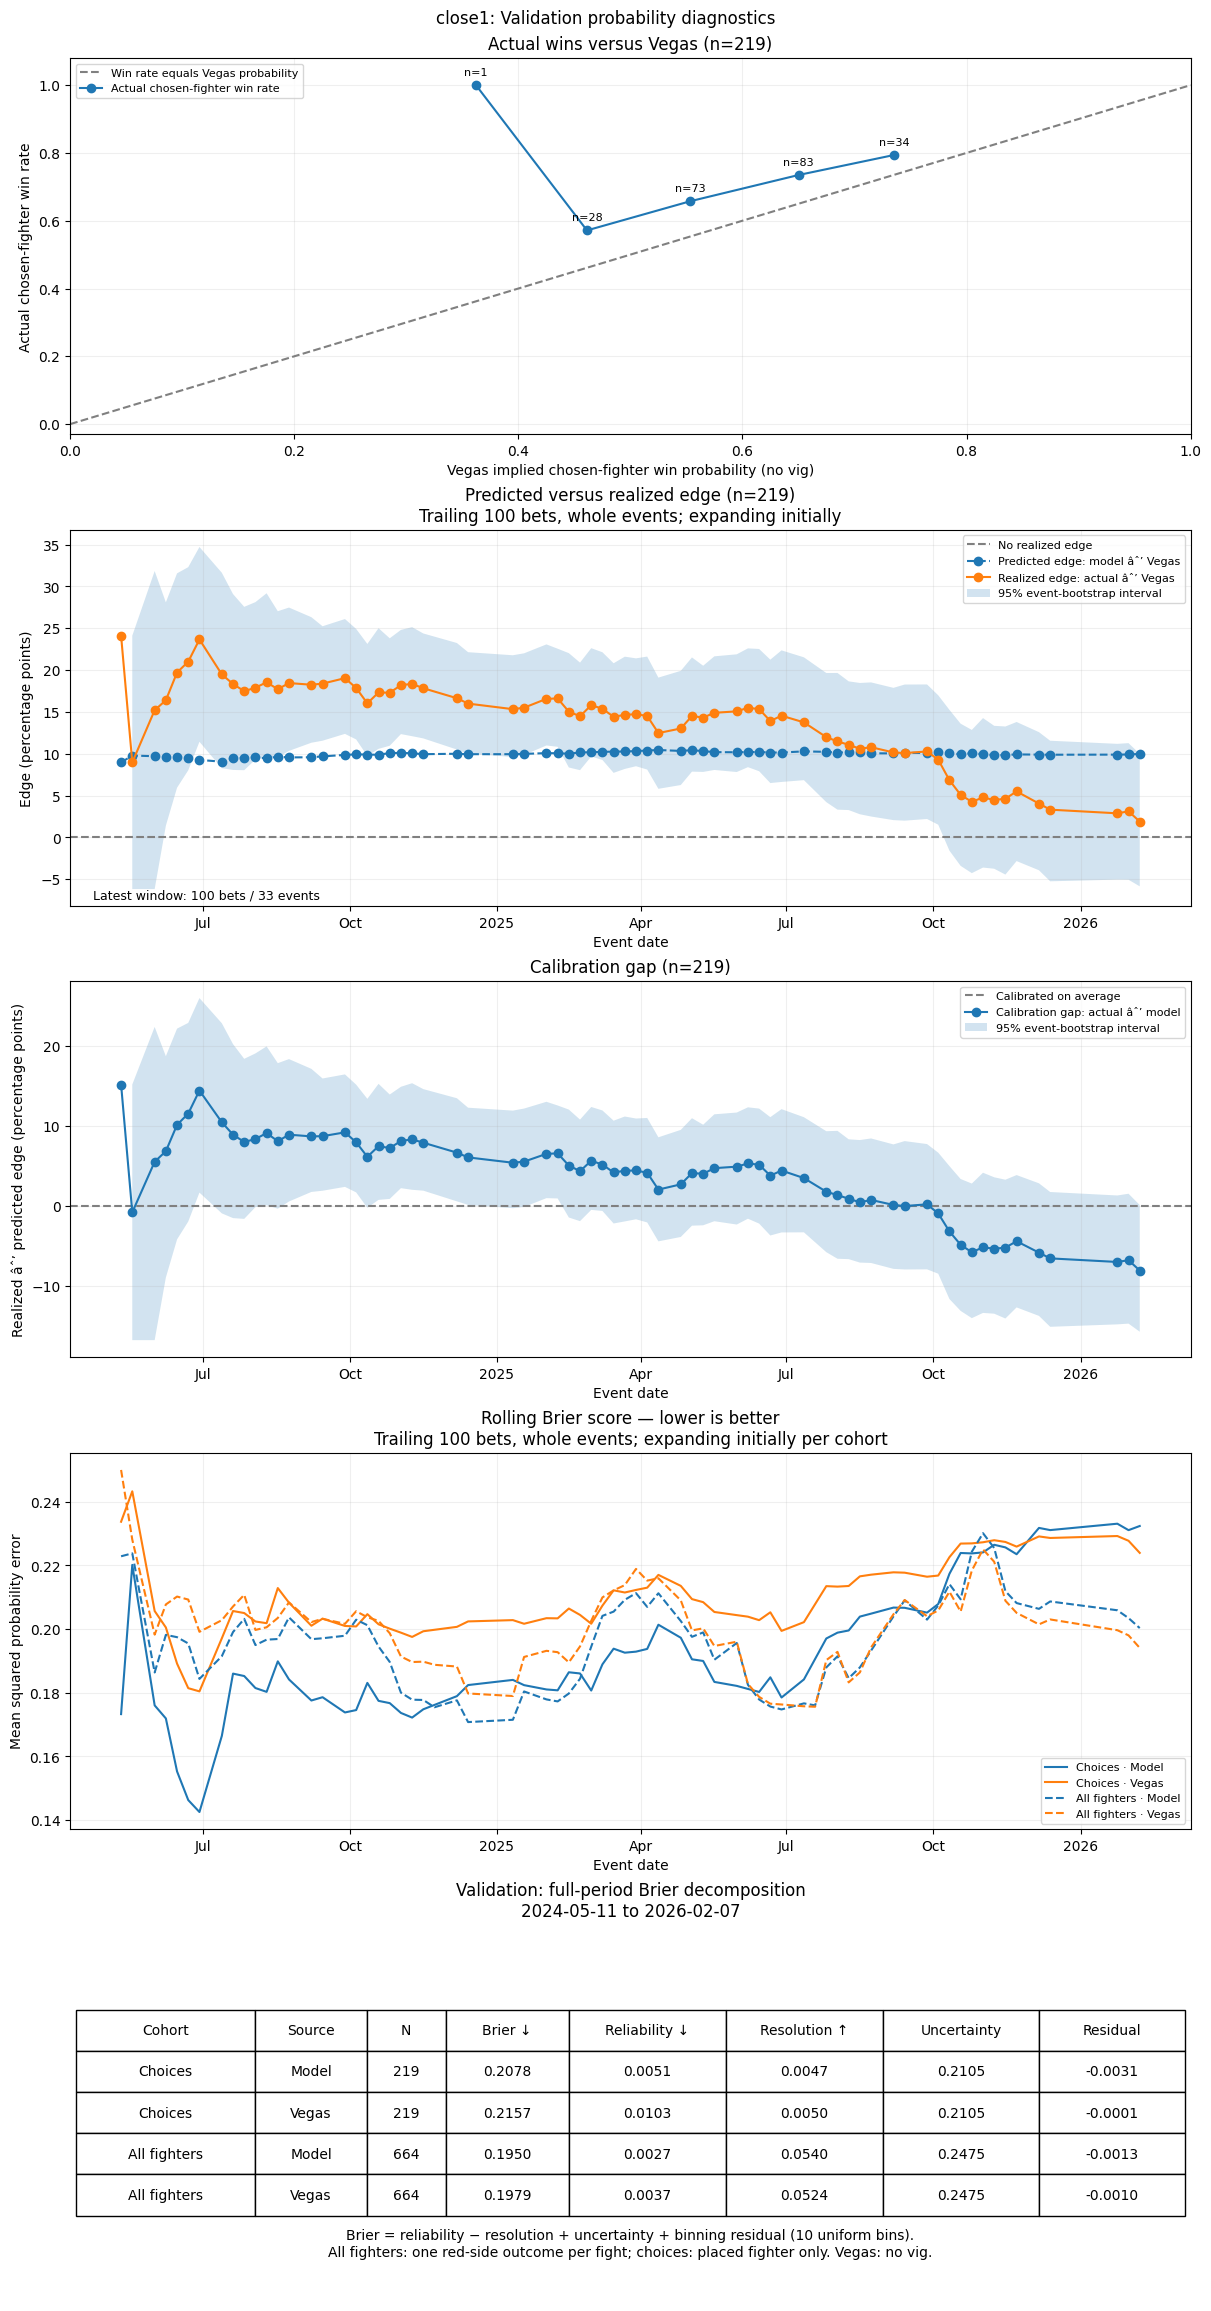

Saved moneylines, parlays, and plots: C:\Users\jcmar\my_files\SportsBetting\Data\backtest_results\model_comparisons\kelly_params / train_val_open_with_close1_regularized_decay_*
Betting parameters: C:\Users\jcmar\my_files\SportsBetting\Data\kelly_params\close2.json
Predictions: C:\Users\jcmar\my_files\SportsBetting\Data\model_comparisons\lr_open_close\report_predictions\train\open\regularized\val_with_close2.csv
close2: decay enabled


{'z': 1.06,
 'N': 123,
 'N_parlay': 43,
 'mdd': 0.56,
 'mdd_parlay': 0.26,
 'moneyline_max_american': None,
 'decay_rates': {'k_down': 38.139591603478735,
  'k_up': 0.0019978853920430734,
  'k_parlay_down': 1.614251913567895,
  'k_parlay_up': 0.07383383104952941},
 'moneyline_min_american': -200.0}

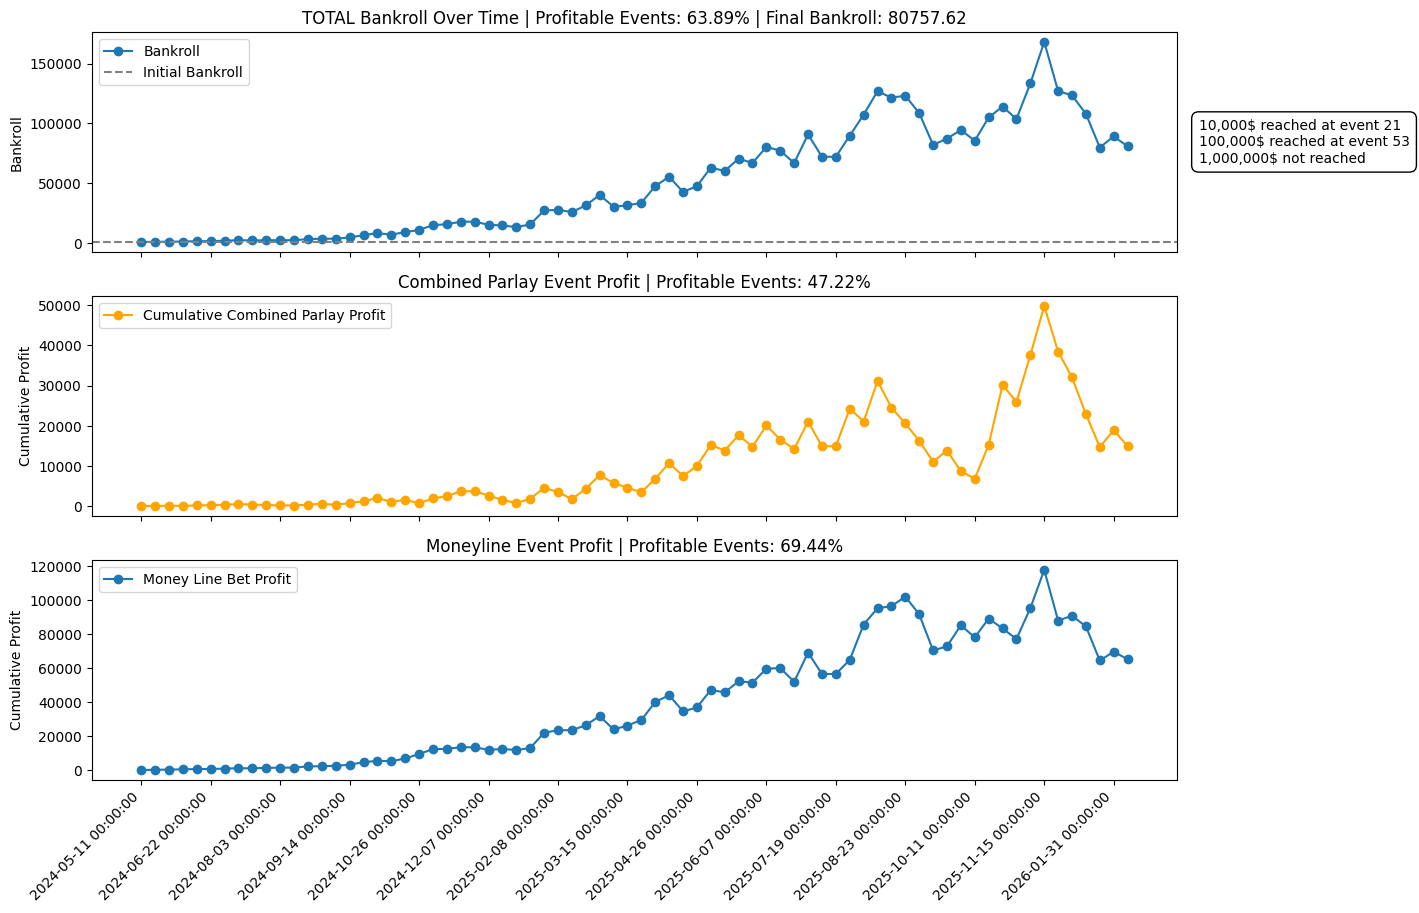

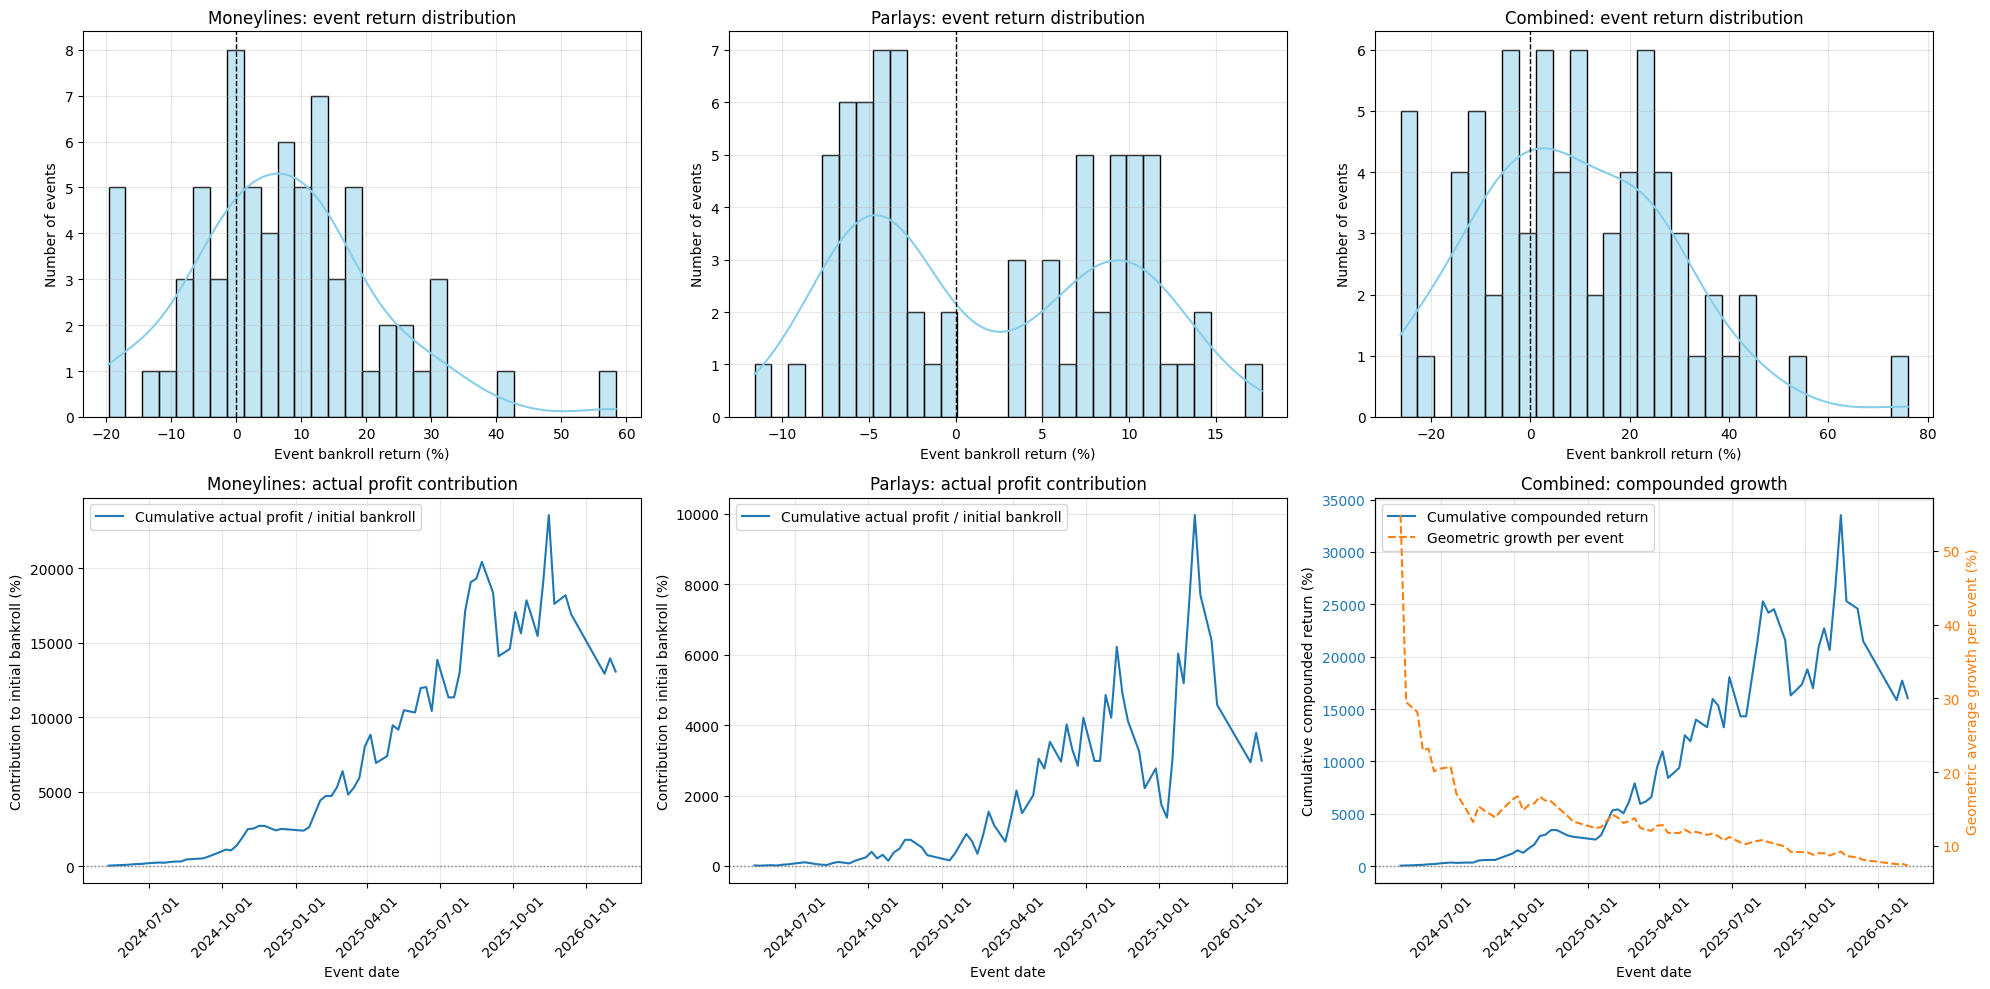

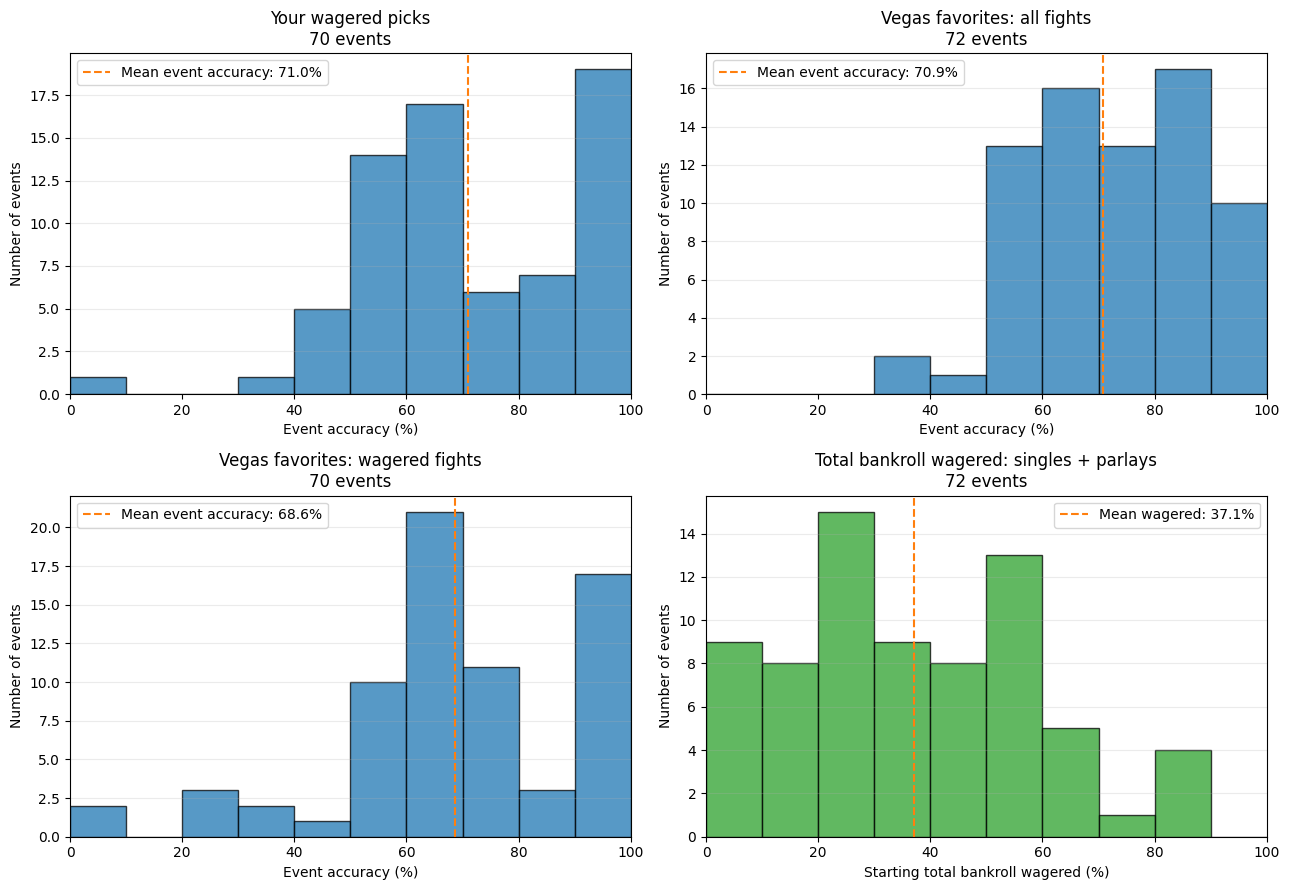

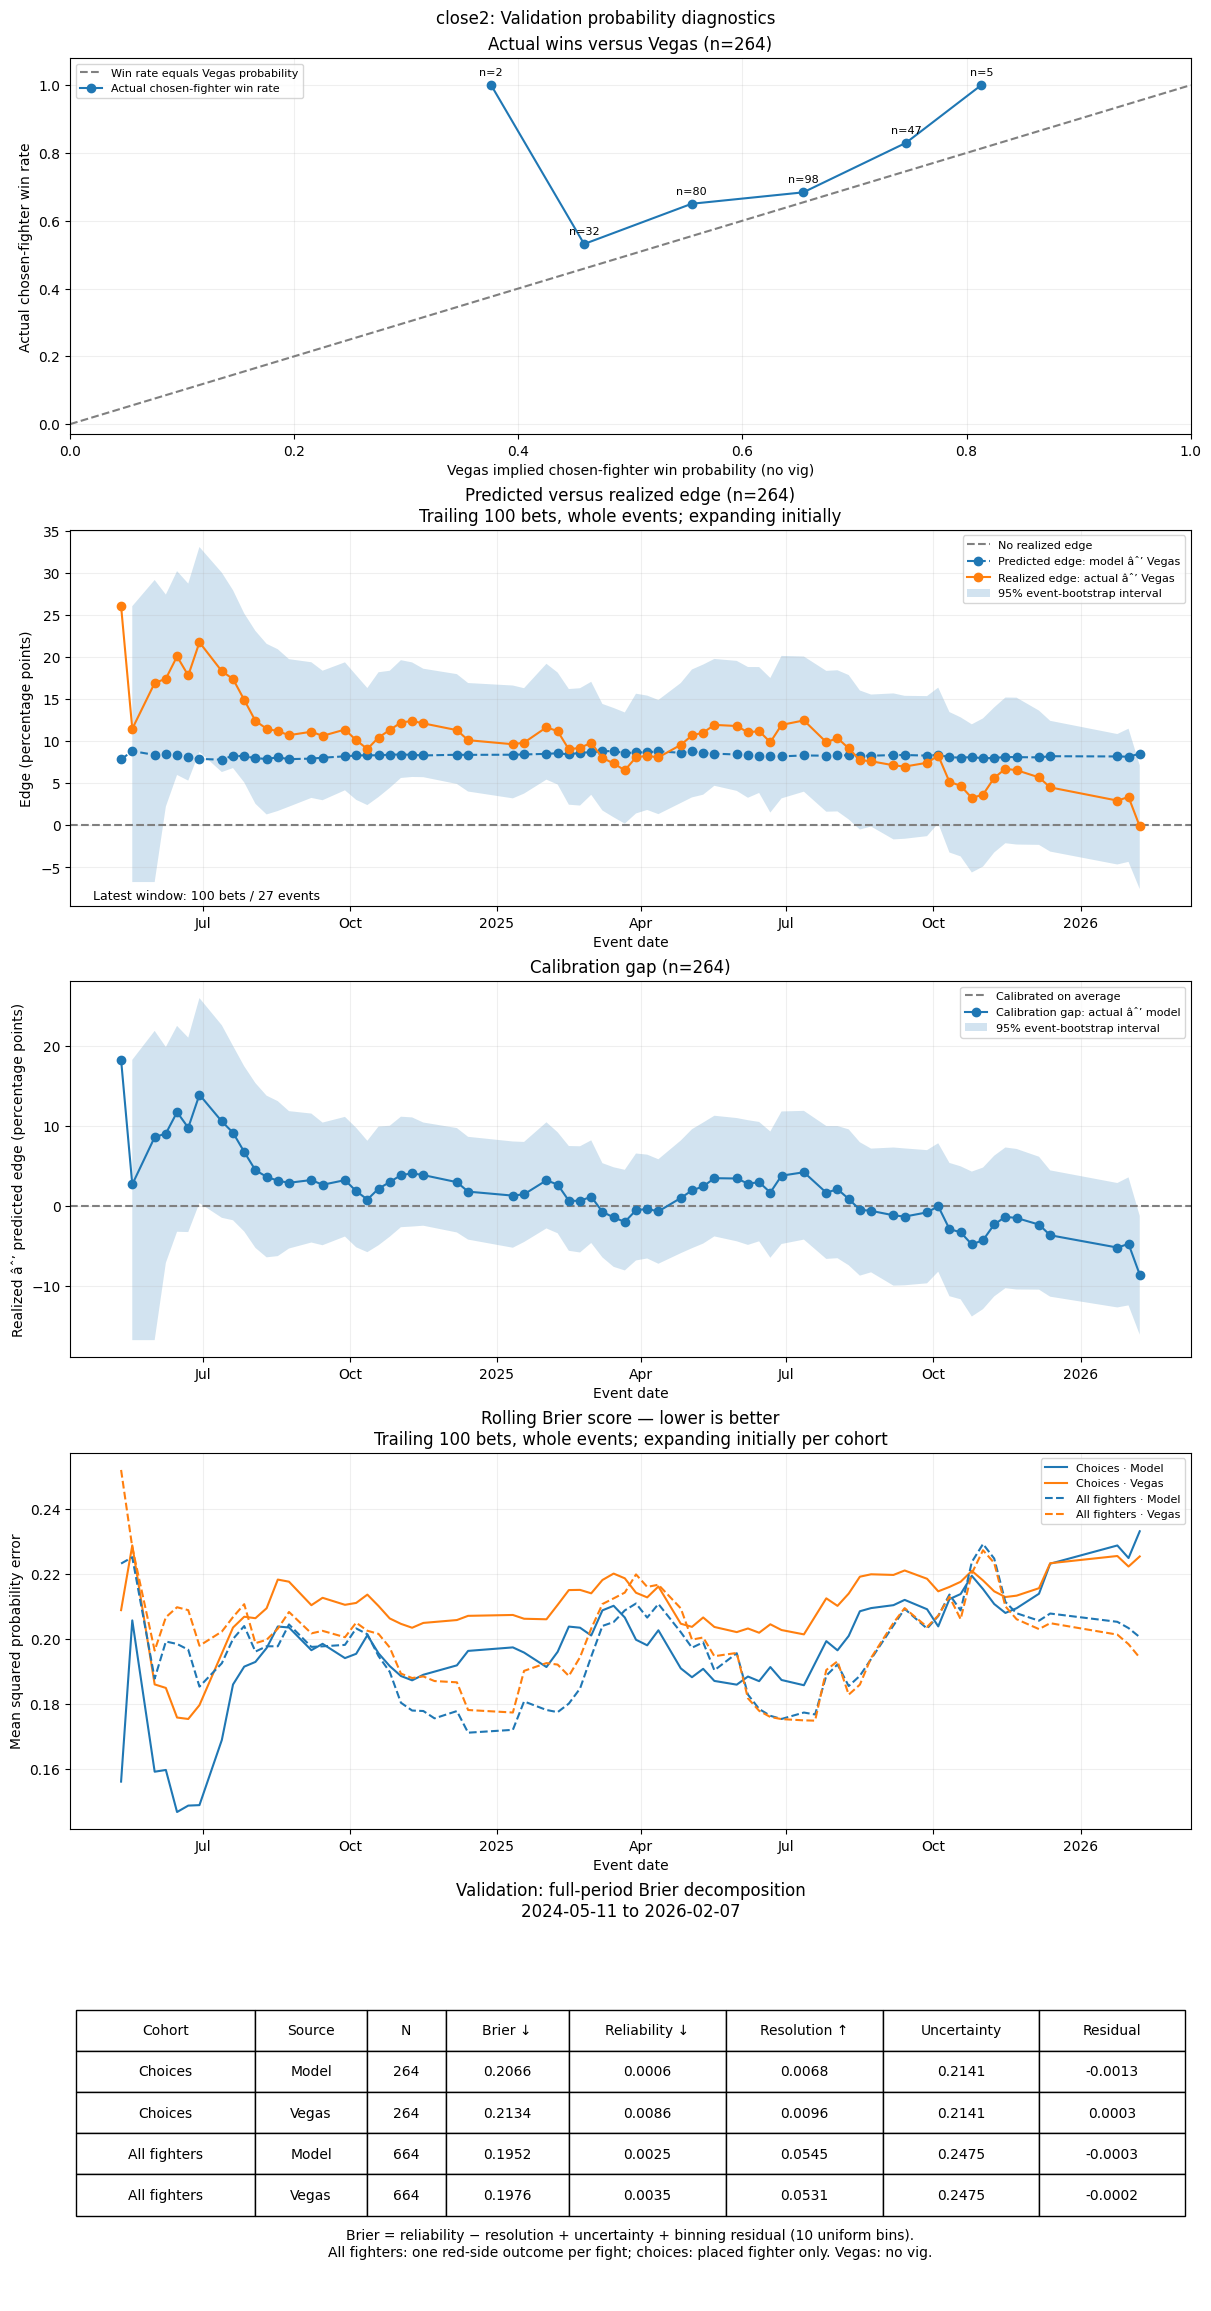

Saved moneylines, parlays, and plots: C:\Users\jcmar\my_files\SportsBetting\Data\backtest_results\model_comparisons\kelly_params / train_val_open_with_close2_regularized_decay_*


In [5]:
for market in ("open", "close1", "close2"):
    moneylines, parlays = plot_comparison_results(
        fit_mode="train",
        model_type='open',
        probability_model="regularized",
        split="val",
        odds_type=market,
        params_dir=settings.data_dir / "kelly_params",
    )